# Session 4 (Finger-tapping sequence learning): rounds, learning and a new pattern

**Same task as Session 3, Part 2.** Assumed protocol (the same as Session 3 Part 2; no timing notes
were provided for this session, so the schedule is located from the data):

| Phase | Rounds | What |
|---|---|---|
| Still baseline | | 30 s sitting still |
| Practice pattern | 1–13 | 15 s tapping, 10 s rest, repeated |
| New pattern | 14–17 | 15 s tapping, 10 s rest, repeated |

**Hypotheses** (as in Session 3 Part 2):
1. **Learning:** as the practice pattern becomes familiar it needs less effort, so frontal theta
   should be **lower** and parietal alpha **higher** in late practice (rounds 10–13) than early
   practice (rounds 1–4).
2. **New pattern:** switching to an unfamiliar pattern should need more effort again, so theta
   should be **higher** and alpha **lower** in rounds 14–17 than in late practice (rounds 10–13).
   This is the stronger test: the new-pattern rounds come last, so fatigue would push them the
   same way as late practice.

**Recording setup:** the Session 1–2 cap layout (T9/T10/P9/P10; no mastoids or Cz). **Fz works
in this session**, so frontal-midline theta is measured at **Fz** directly (in Session 3 Fz was dead
and F3+F4 had to stand in). F3 is excluded (too noisy: about 35% of its 2 s windows are clean in the raw
data and 65% after ICA, against at least 94% for the other channels). All analysis is average-referenced; 1000 Hz; p-values are descriptive only.

Shared analysis code: `processing/analysis.py` and `processing/cleaning.py`.

In [1]:
import sys
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session
from processing.analysis import (
    band_filter, periodic_metrics, periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars,
    plot_quality, plot_relative_bars, plot_segments, plot_spectra, roi_spectrum, window_spectra,
)
from processing.cleaning import ica_clean, prepare

plt.rcParams["figure.dpi"] = 72

SESSION_DIR = REPO_ROOT / "data" / "Session 4"
BAD_CHANNELS = ["F3"]                 # too noisy (≈65% clean windows even after ICA)
THETA_SITE, THETA_CHANNELS = "Fz", ["Fz"]
ALPHA_SITE = "Pz"
LOCAL_UTC_OFFSET = timedelta(hours=-5)   # EST

# Protocol (same as Session 3 Part 2)
BASELINE_LEN, ROUND_LEN, ROUND_PERIOD, N_ROUNDS = 30.0, 15.0, 25.004, 17
TRANSIENT_UV = 500   # 1 s bins where any channel exceeds this (1–40 Hz) are excluded
PATTERN = ["practice"] * 13 + ["new"] * 4
GROUPS = {"Early practice (rounds 1–4)": range(0, 4), "Middle practice (rounds 5–9)": range(4, 9),
          "Late practice (rounds 10–13)": range(9, 13), "New pattern (rounds 14–17)": range(13, 17)}

In [2]:
session = load_session(SESSION_DIR)
recording = session.segments[0]
start_local = pd.Timestamp(session.raw.info["meas_date"].replace(tzinfo=None) + LOCAL_UTC_OFFSET)
print(f"Recording: {start_local:%H:%M:%S} to {start_local + timedelta(seconds=recording.times[-1]):%H:%M:%S} "
      f"local, {recording.times[-1]:.1f} s at {session.sfreq:g} Hz; channels: {', '.join(session.ch_names)}")

Recording: 10:40:22 to 10:48:05 local, 462.9 s at 1000 Hz; channels: Fp1, Fp2, F9, F7, F3, Fz, F4, F8, F10, T9, T7, C3, C4, T8, T10, P9, P7, P3, Pz, P4, P8, P10, O1, O2


## 1. Locating the rounds in the recording

There are no timing notes for this session, so the schedule is found from the data. During each
15 s round the participant taps and holds still; during each 10 s rest they blink and look around.
That makes eye activity at Fp1/Fp2 (1–4 Hz) drop in every round, which in Session 3 Part 2 matched
the noted schedule closely. The round-1 start time that best lines up a 17-round, 25 s-period schedule
with this signal is used. Two checks: the eye signal should repeat every 25 s, and every round should
show the drop. Large transients (any channel above 500 µV in a 1 s bin) are marked and excluded.

**Why this plot:** every per-round result depends on the rounds being placed correctly, so this
shows how well the schedule fits the data and how sharply the start time is determined.

Transients excluded (s): [0, 1, 4, 5, 17, 18, 107, 116, 117, 169, 450, 461]  (largest 9682 µV at 169 s)


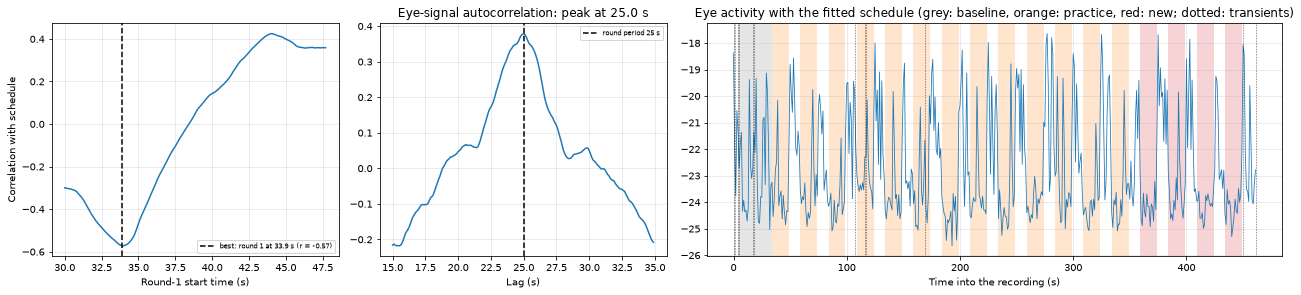

Baseline 3.9–33.9 s; round 1 starts 33.9 s; round 17 ends 449.0 s (recording ends 462.9 s)
Eye activity lower during the round than in the following rest in 17 of 17 rounds


In [3]:
prepared = prepare(recording, BAD_CHANNELS)
sf = int(session.sfreq)
STEP = 0.1  # s

# Large transients: 1 s bins where any channel exceeds TRANSIENT_UV (after 1–40 Hz filtering)
peak = np.abs(recording.copy().filter(1, 40, verbose="error").get_data()).max(axis=0) * 1e6
peak_1s = peak[: len(peak) // sf * sf].reshape(-1, sf).max(axis=1)
transients = [int(t) for t in np.where(peak_1s > TRANSIENT_UV)[0]]
for t_s in transients:
    prepared.annotations.append(t_s - 0.5, 2.0, "BAD_transient")
print(f"Transients excluded (s): {transients}  (largest {peak_1s.max():.0f} µV at {int(np.argmax(peak_1s))} s)")


def log_envelope(band, channels):
    x = prepared.copy().pick(channels).filter(*band, verbose="error").apply_hilbert(envelope=True, verbose="error").get_data()
    x = np.log(x ** 2).mean(axis=0)
    n = int(STEP * session.sfreq)
    return x[: len(x) // n * n].reshape(-1, n).mean(axis=1)


eye = log_envelope((1, 4), ["Fp1", "Fp2"])
t = np.arange(len(eye)) * STEP
starts = np.arange(BASELINE_LEN, t[-1] - (N_ROUNDS - 1) * ROUND_PERIOD - ROUND_LEN, STEP)   # baseline must fit before round 1


def schedule_corr(t1):
    box = np.zeros_like(t)
    for i in range(N_ROUNDS):
        box[(t >= t1 + i * ROUND_PERIOD) & (t < t1 + i * ROUND_PERIOD + ROUND_LEN)] = 1
    m = (t >= t1 - 10) & (t <= t1 + (N_ROUNDS - 1) * ROUND_PERIOD + ROUND_LEN + 5)
    return np.corrcoef(eye[m], box[m])[0, 1]


corr = np.array([schedule_corr(t1) for t1 in starts])
T1 = round(float(starts[np.argmin(corr)]), 1)
ROUNDS = np.array([[T1 + i * ROUND_PERIOD, T1 + i * ROUND_PERIOD + ROUND_LEN] for i in range(N_ROUNDS)])
BASELINE = np.array([T1 - BASELINE_LEN, T1])

e0 = eye - eye.mean()
lags = np.arange(int(15 / STEP), int(35 / STEP))
ac = np.array([np.corrcoef(e0[:-L], e0[L:])[0, 1] for L in lags])
per_round_drop = [eye[(t >= b) & (t < min(b + 10, t[-1]))].mean() - eye[(t >= a) & (t < b)].mean() for a, b in ROUNDS]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 2]))
axes[0].plot(starts, corr, color="C0")
axes[0].axvline(T1, color="k", ls="--", label=f"best: round 1 at {T1} s (r = {corr.min():+.2f})")
axes[0].set_xlabel("Round-1 start time (s)")
axes[0].set_ylabel("Correlation with schedule")
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.3)
axes[1].plot(lags * STEP, ac, color="C0")
axes[1].axvline(ROUND_PERIOD, color="k", ls="--", label=f"round period {ROUND_PERIOD:.0f} s")
axes[1].set_xlabel("Lag (s)")
axes[1].set_title(f"Eye-signal autocorrelation: peak at {lags[np.argmax(ac)] * STEP:.1f} s")
axes[1].legend(fontsize=7)
axes[1].grid(alpha=0.3)
k = int(1 / STEP)
axes[2].plot(t[: len(eye) // k * k : k], eye[: len(eye) // k * k].reshape(-1, k).mean(axis=1), color="C0", lw=0.8)
for i, (a, b) in enumerate(ROUNDS):
    axes[2].axvspan(a, b, color="C3" if PATTERN[i] == "new" else "C1", alpha=0.2, lw=0)
axes[2].axvspan(*BASELINE, color="0.6", alpha=0.25, lw=0)
for t_s in transients:
    axes[2].axvline(t_s, color="k", lw=0.6, ls=":")
axes[2].set_xlabel("Time into the recording (s)")
axes[2].set_title("Eye activity with the fitted schedule (grey: baseline, orange: practice, red: new; dotted: transients)")
axes[2].grid(alpha=0.3)
fig.tight_layout()
plt.show()
print(f"Baseline {BASELINE[0]:.1f}–{BASELINE[1]:.1f} s; round 1 starts {ROUNDS[0, 0]:.1f} s; round 17 ends {ROUNDS[-1, 1]:.1f} s "
      f"(recording ends {recording.times[-1]:.1f} s)")
print(f"Eye activity lower during the round than in the following rest in {sum(d > 0 for d in per_round_drop)} of {N_ROUNDS} rounds")

## 2. Data quality per phase

The baseline and each group of rounds (rests left out) are cut from the prepared recording
(F3 dropped; 1–100 Hz; 60 Hz notch; average reference), with the transients marked as bad.

**Why this plot:** it shows whether any phase or channel has too little clean EEG to trust before comparing them.

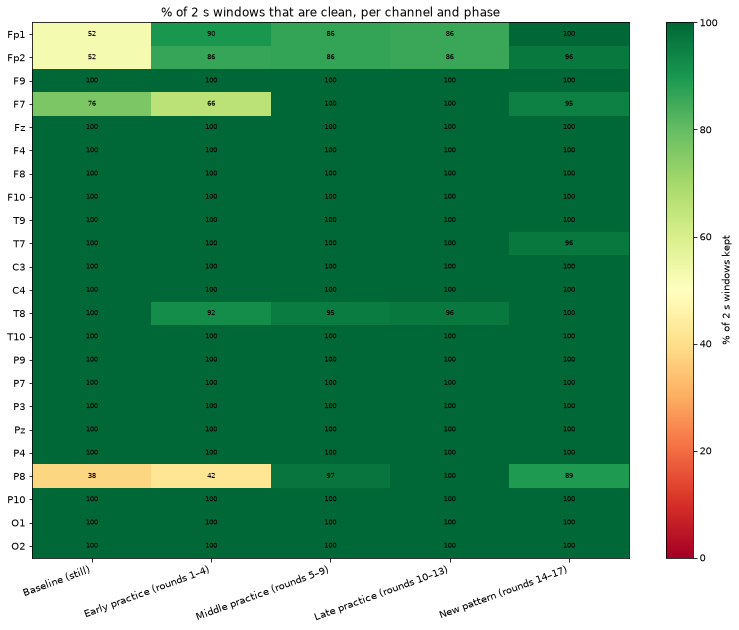

In [4]:
def cut(raw, a, b):
    """Times a, b are seconds into the original recording; works for cropped copies too."""
    t0 = raw.first_time - recording.first_time
    return raw.copy().crop(tmin=max(0.0, a - t0), tmax=b - t0, include_tmax=False, verbose="error")


def concat(raws):
    return mne.concatenate_raws([r.copy() for r in raws], verbose="error")


def phase_data(raw):
    """{phase name: Raw} with baseline and each round group (rounds joined end to end)."""
    out = {"Baseline (still)": cut(raw, *BASELINE)}
    for name, idx in GROUPS.items():
        out[name] = concat([cut(raw, *ROUNDS[i]) for i in idx])
    return out


phases = phase_data(prepared)
plot_quality([window_spectra(r) for r in phases.values()], list(phases), "% of 2 s windows that are clean, per channel and phase")

## 3. Band plots: late practice (rounds 10–13) vs new pattern (rounds 14–17)

These two groups are adjacent in time, so they differ mainly in how familiar the pattern was.
The four rounds of each group are joined end to end (dashed lines mark where one round ends and
the next begins).

In [5]:
raw_rounds = recording.copy().drop_channels(BAD_CHANNELS)
late_new_labels = ["Late practice (rounds 10–13)", "New pattern (rounds 14–17)"]
round_len = ROUNDS[0, 1] - ROUNDS[0, 0]
edges = [(round_len * (i + 1), "") for i in range(3)]
marks = [edges, edges]


def group_rounds(raw, idx, transform=None):
    return concat([transform(cut(raw, *ROUNDS[i])) if transform else cut(raw, *ROUNDS[i]) for i in idx])

### 3.1 Original data (no filtering, original reference)

**Why this plot:** check signal quality before any processing: drift, noisy channels, and movement or blink artifacts that filtering could hide or smear.

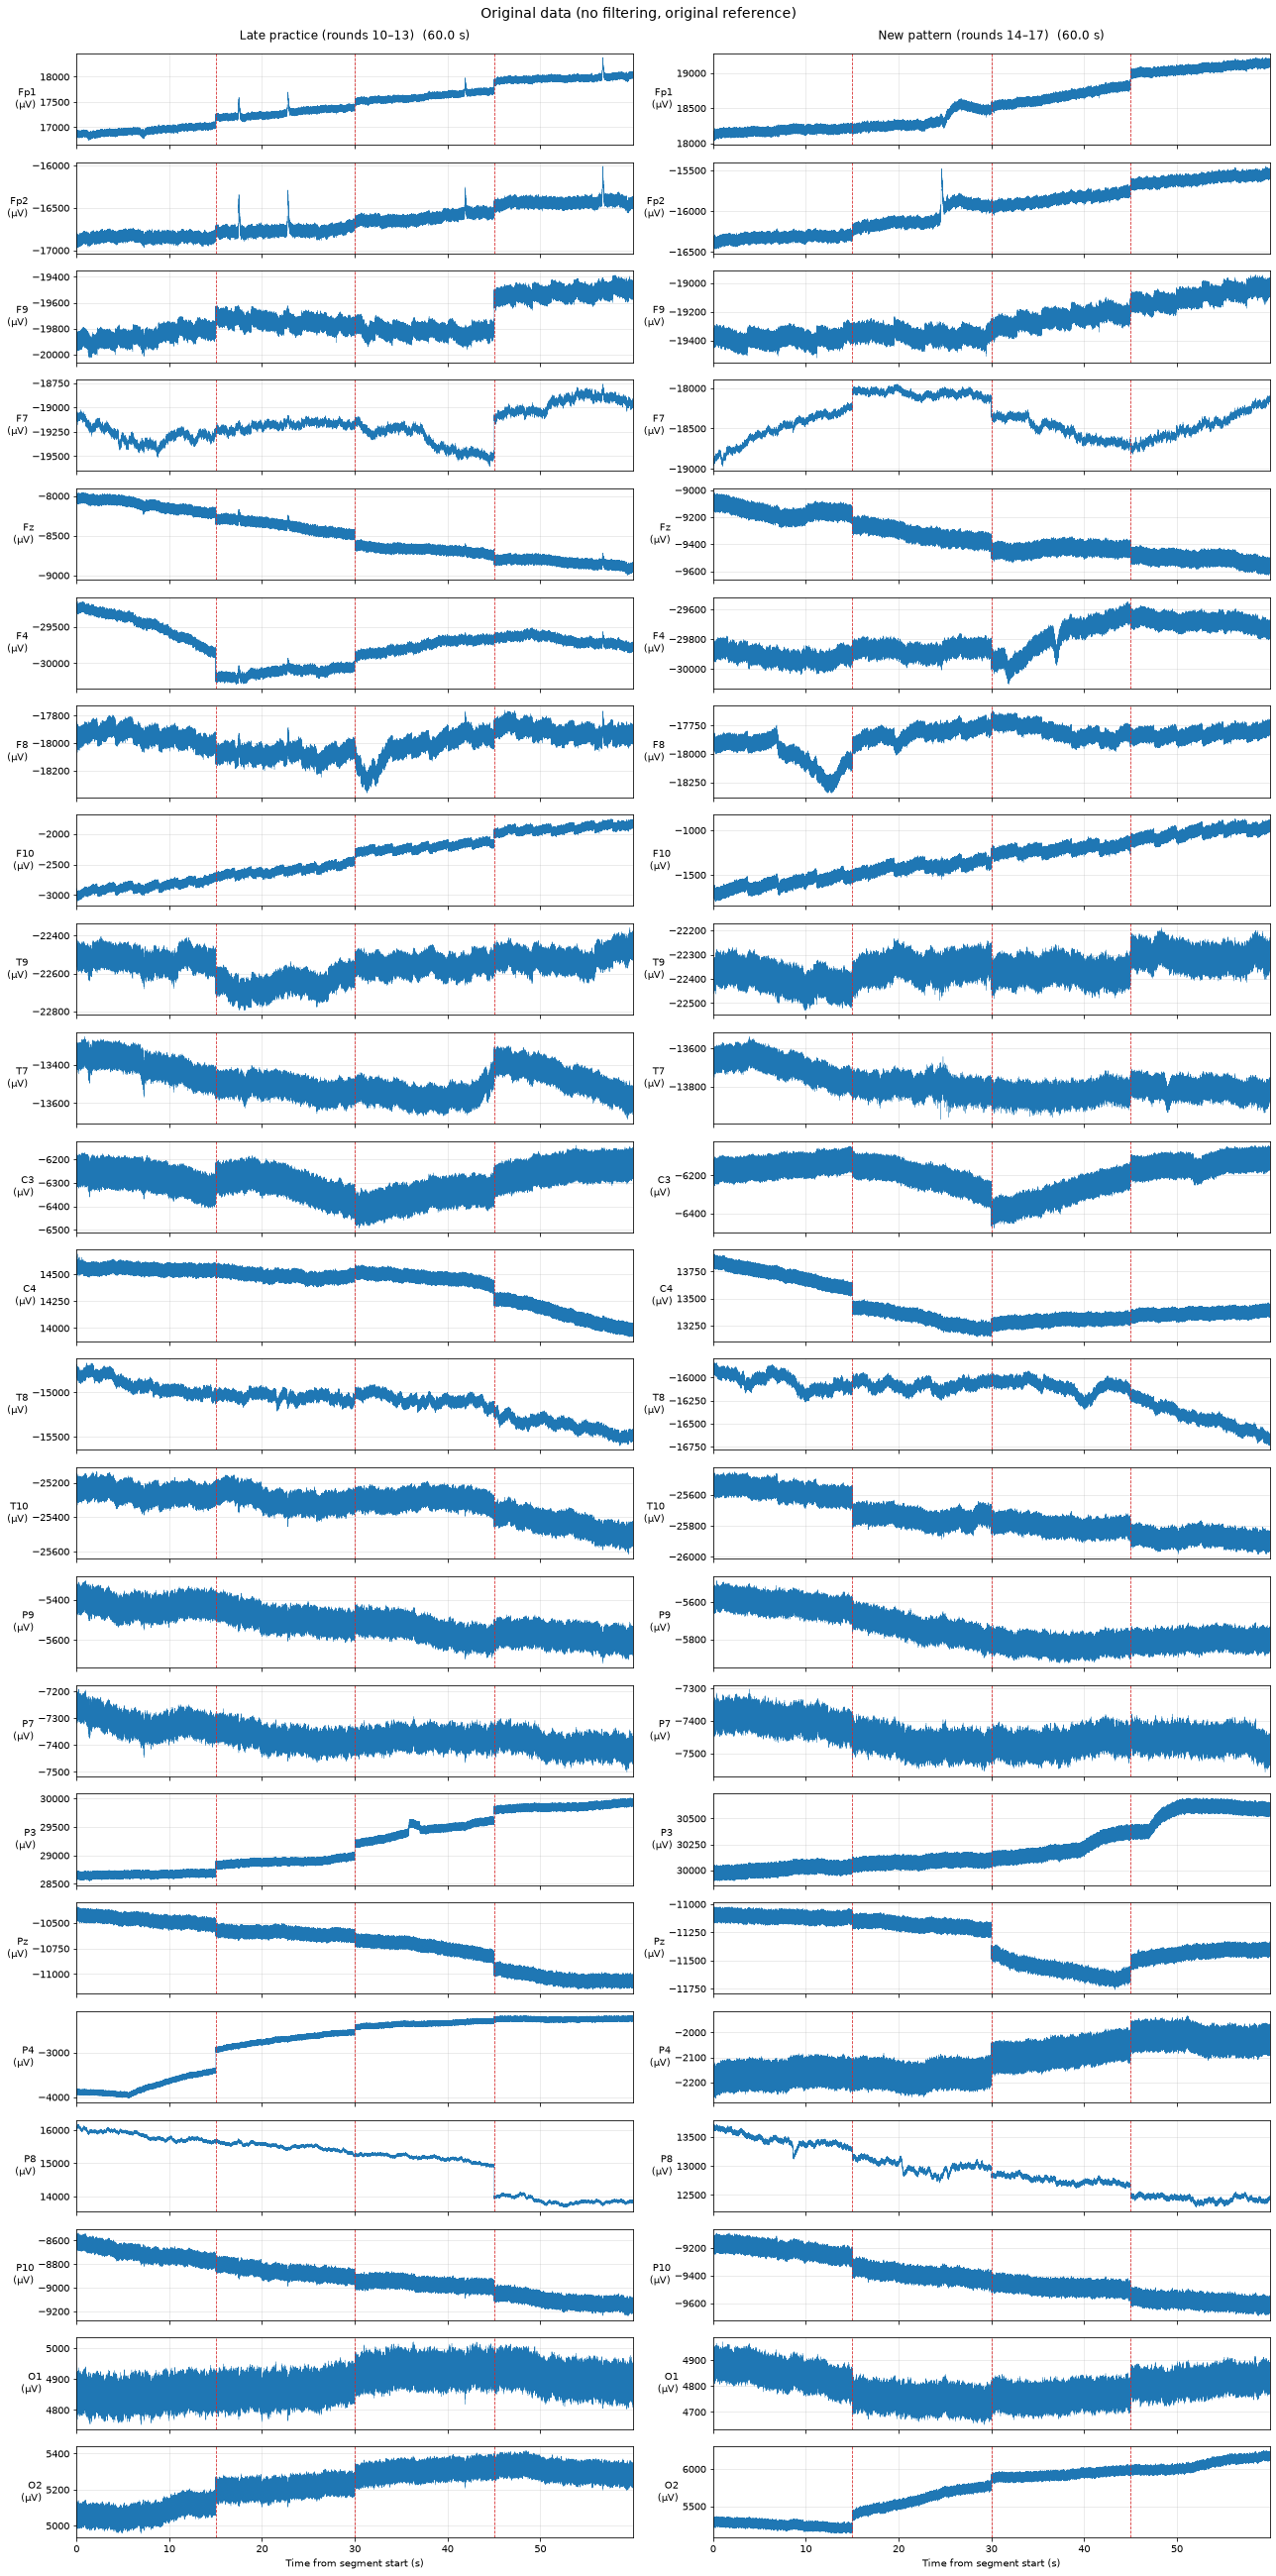

In [6]:
plot_segments([group_rounds(raw_rounds, range(9, 13)), group_rounds(raw_rounds, range(13, 17))], late_new_labels, "Original data (no filtering, original reference)", sharey_rows=False, marks=marks)

### 3.2 Theta band (4–8 Hz)

**Why this plot:** frontal-midline theta (Fz) rises with mental effort, so higher theta for the new pattern than for the practised one would suggest it was more demanding.

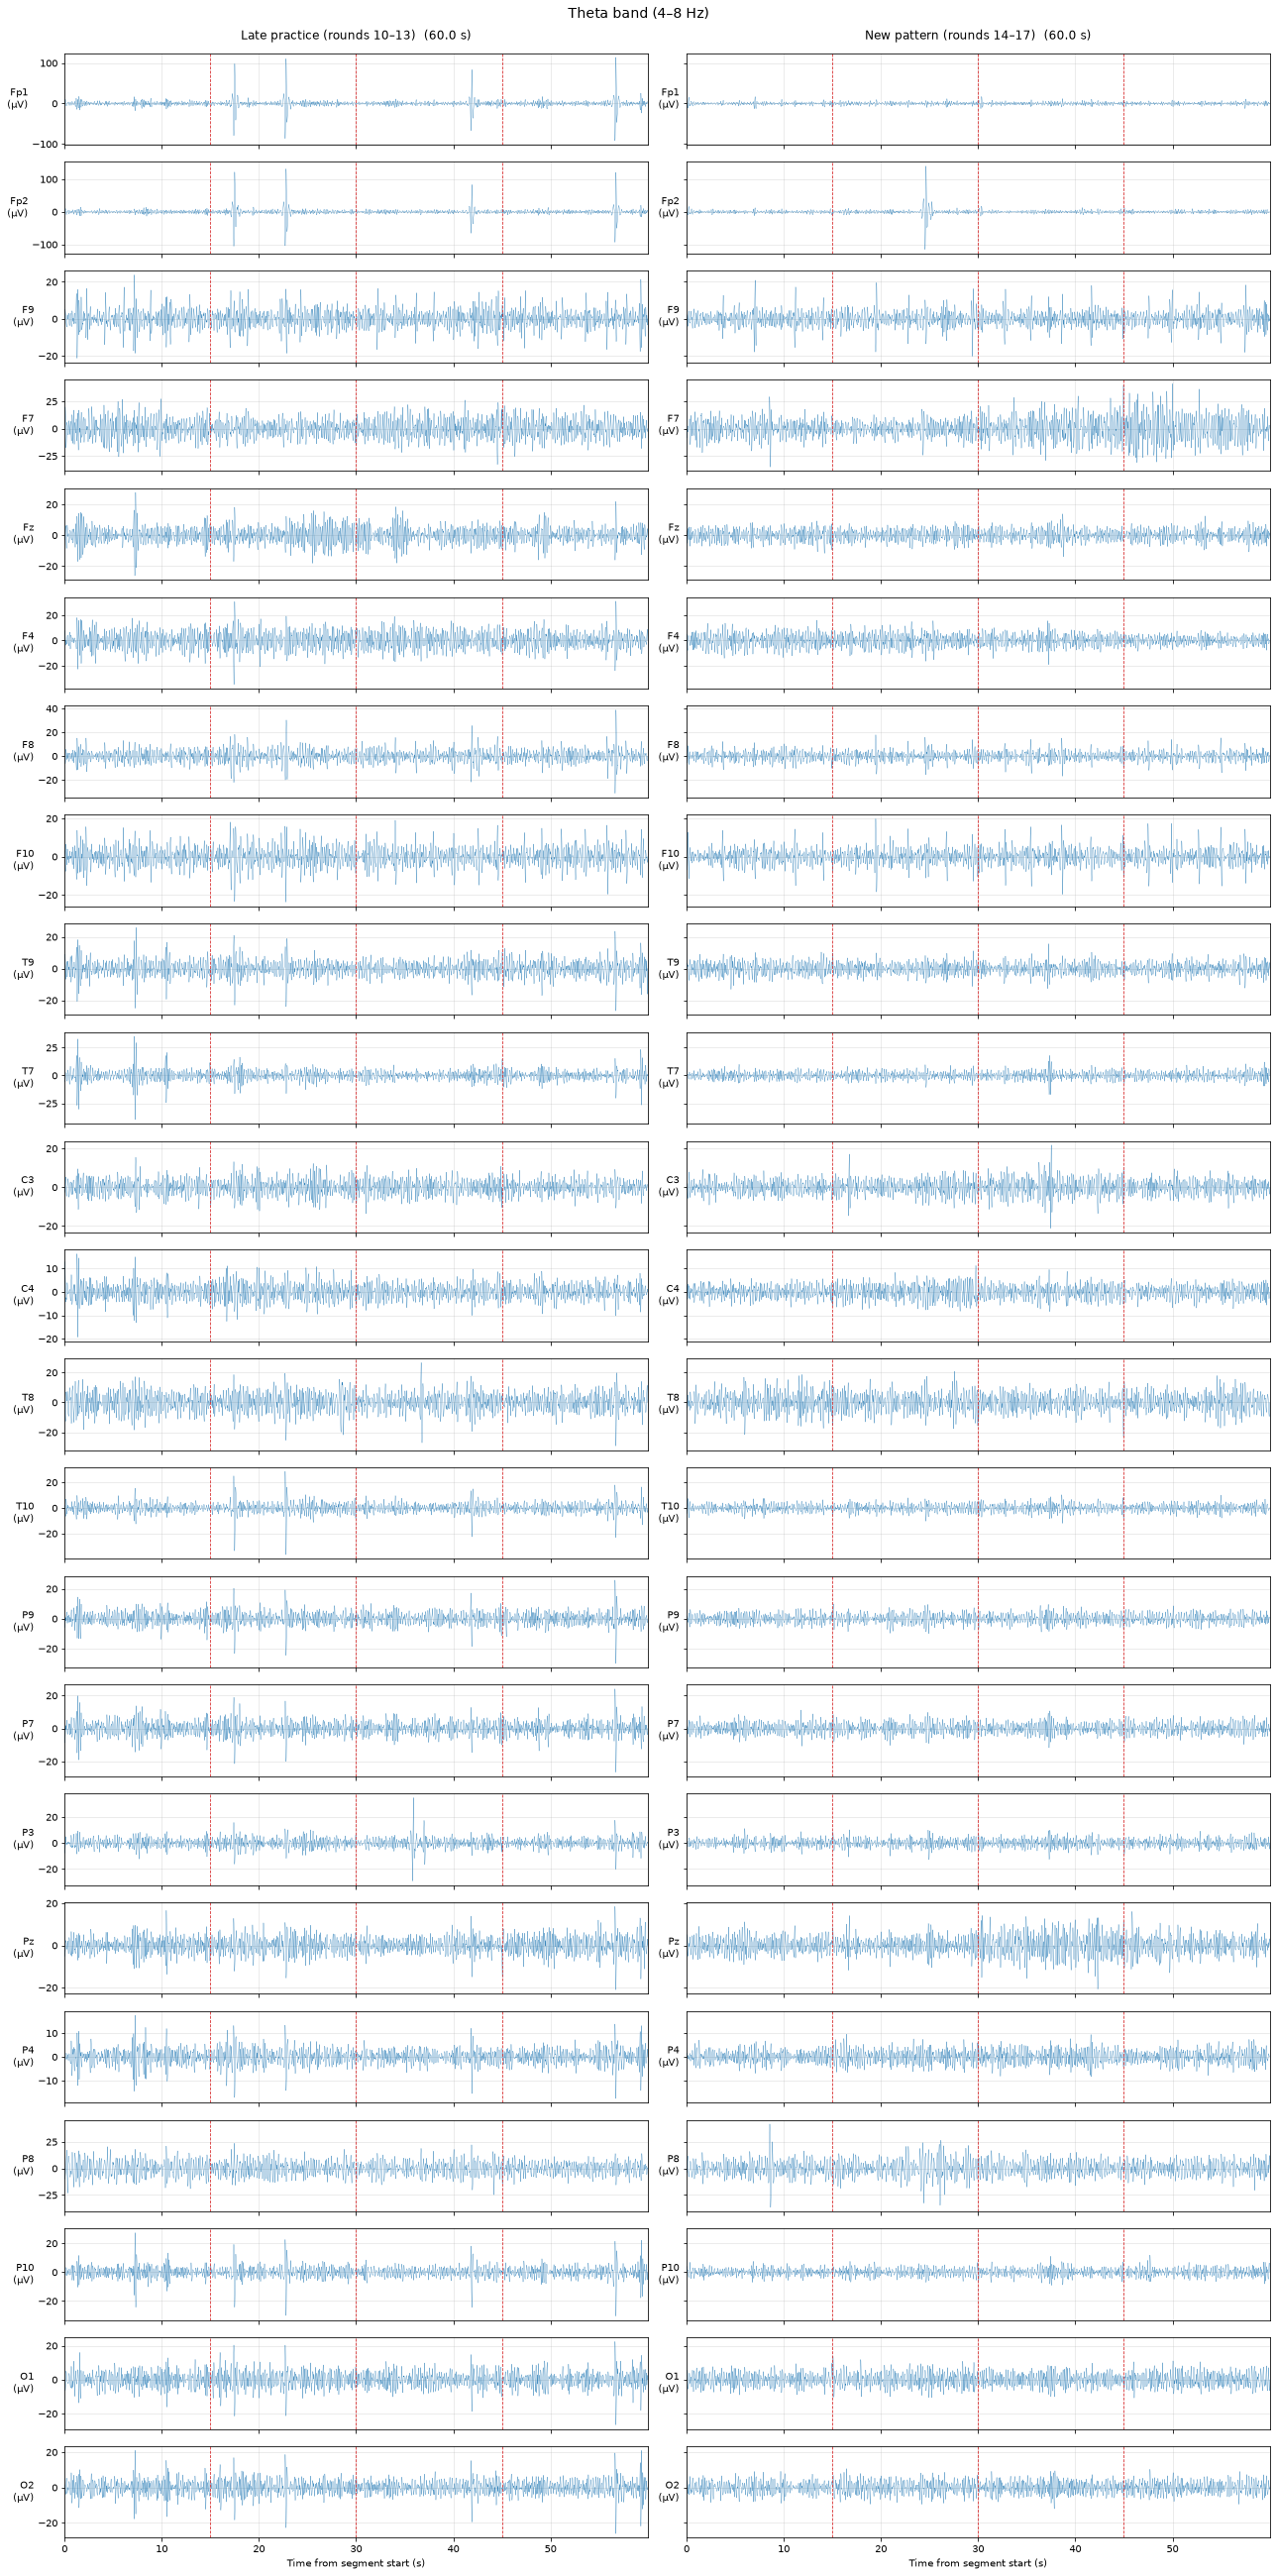

In [7]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 4, 8)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 4, 8))], late_new_labels, "Theta band (4–8 Hz)", marks=marks)

### 3.3 Alpha band (8–13 Hz)

**Why this plot:** parietal alpha drops when a task needs more attention, so lower alpha for the new pattern would suggest it demanded more.

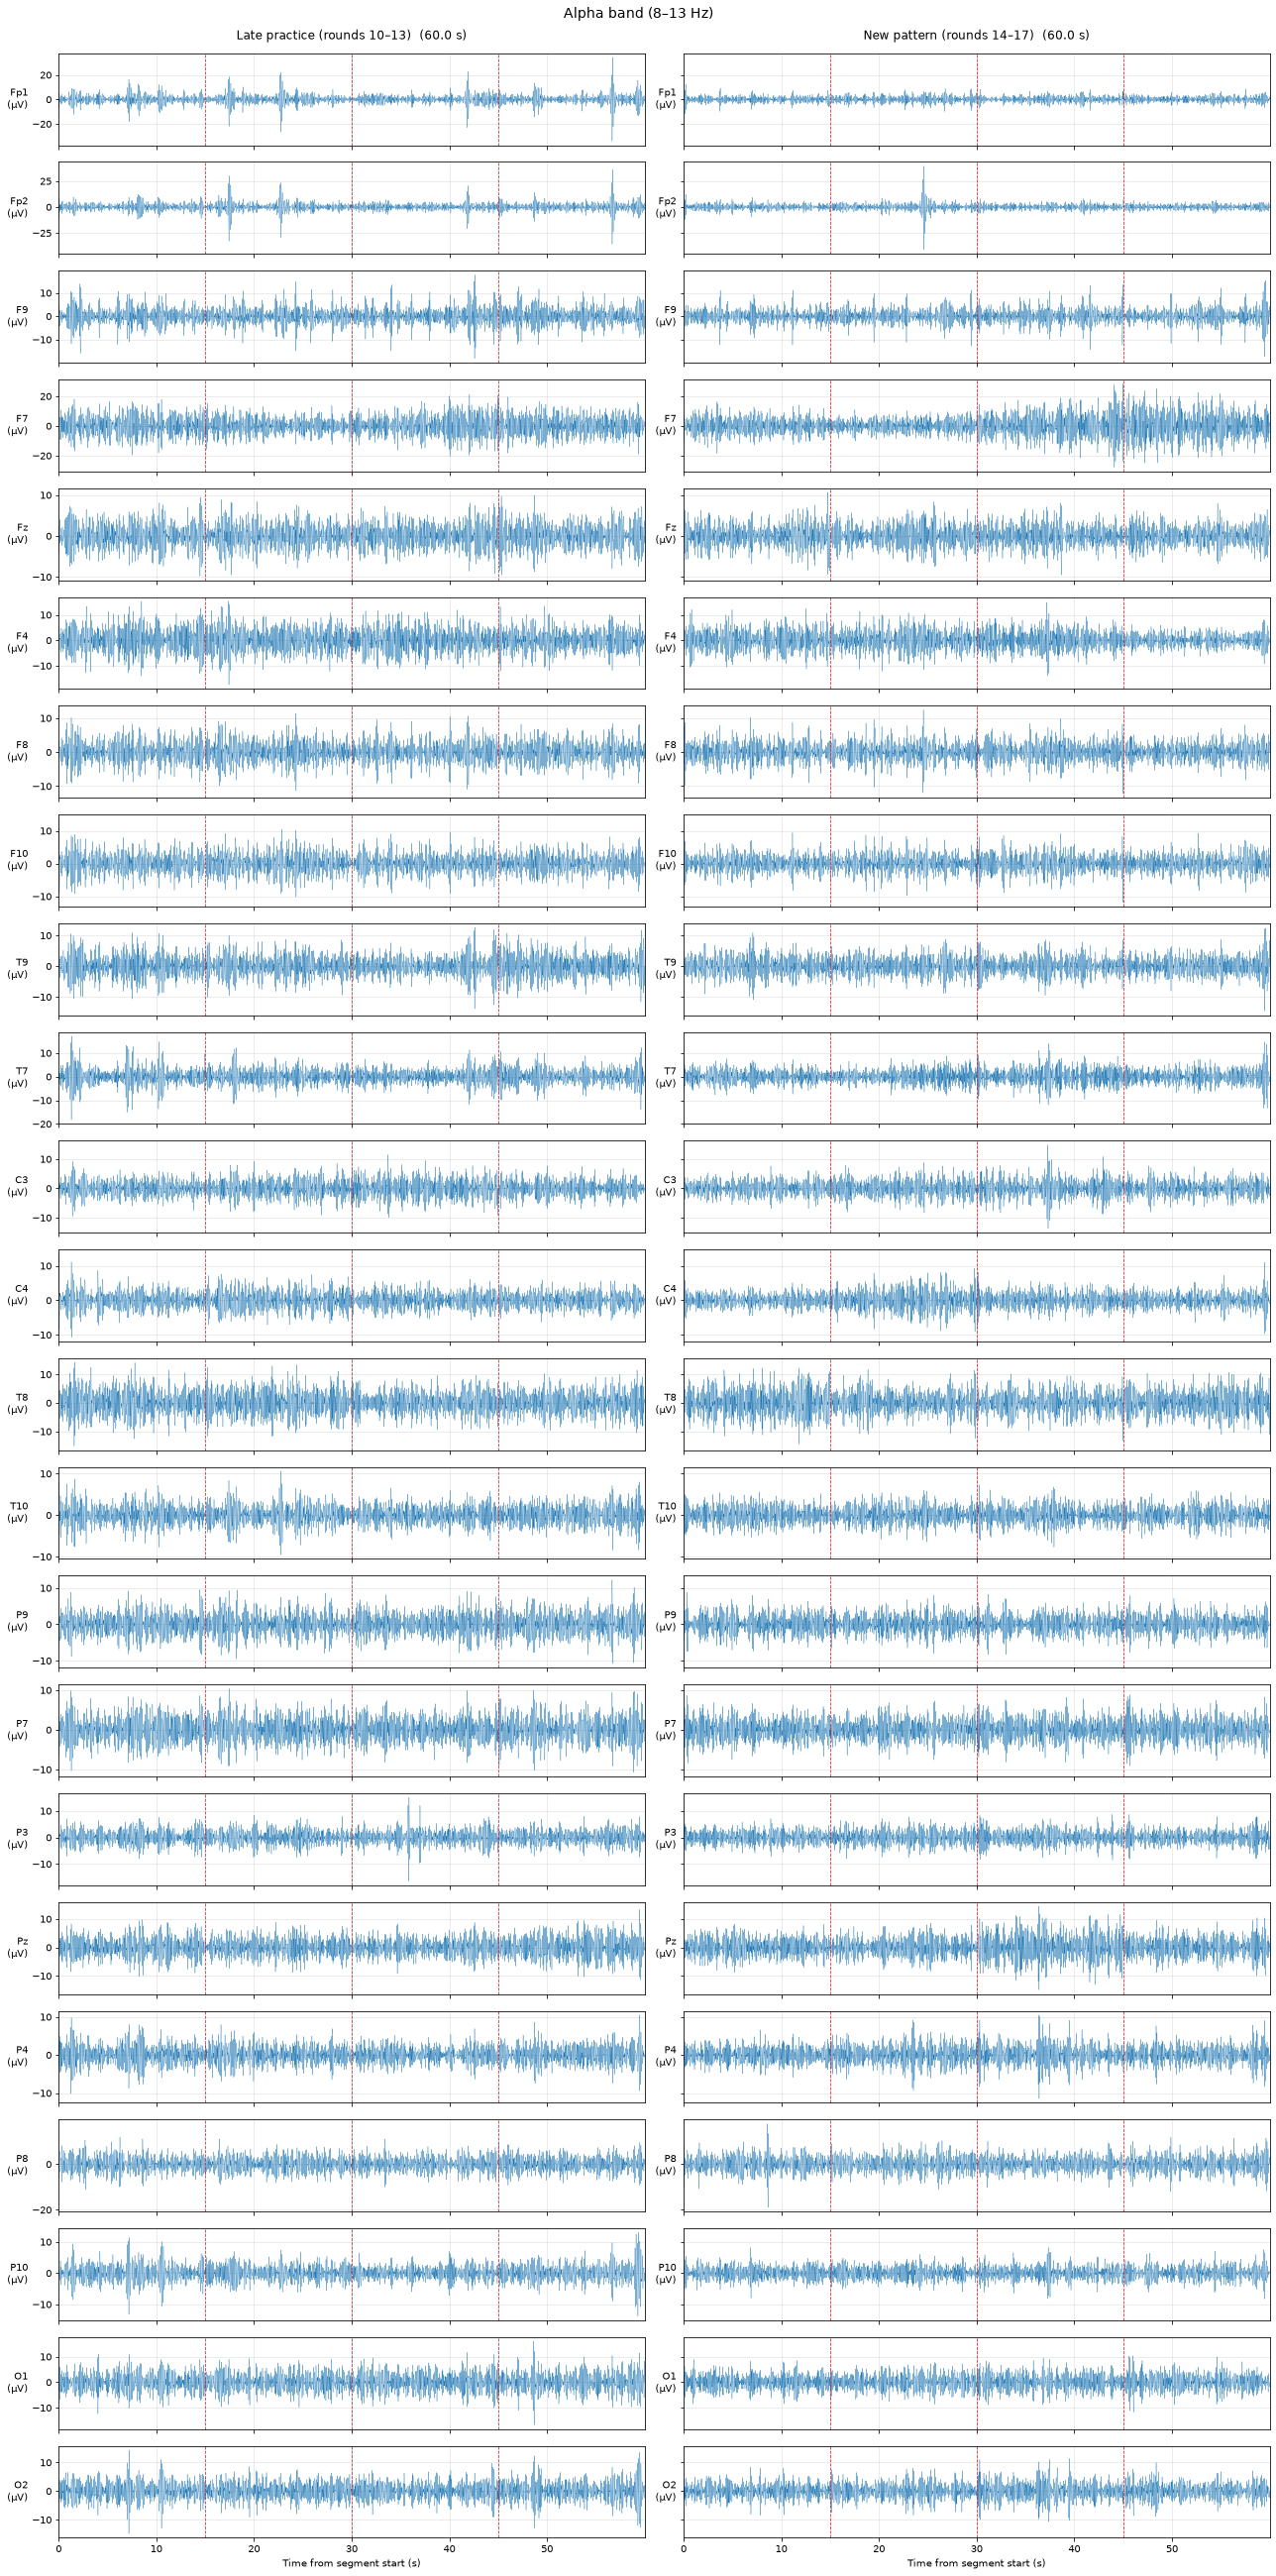

In [8]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 8, 13)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 8, 13))], late_new_labels, "Alpha band (8–13 Hz)", marks=marks)

### 3.4 Beta band (13–30 Hz)

**Why this plot:** beta mostly tracks movement (over C4 it drops while the left-hand fingers tap), so it shows whether the tapping itself differed between patterns. It is a confound to watch, not a measure of effort.

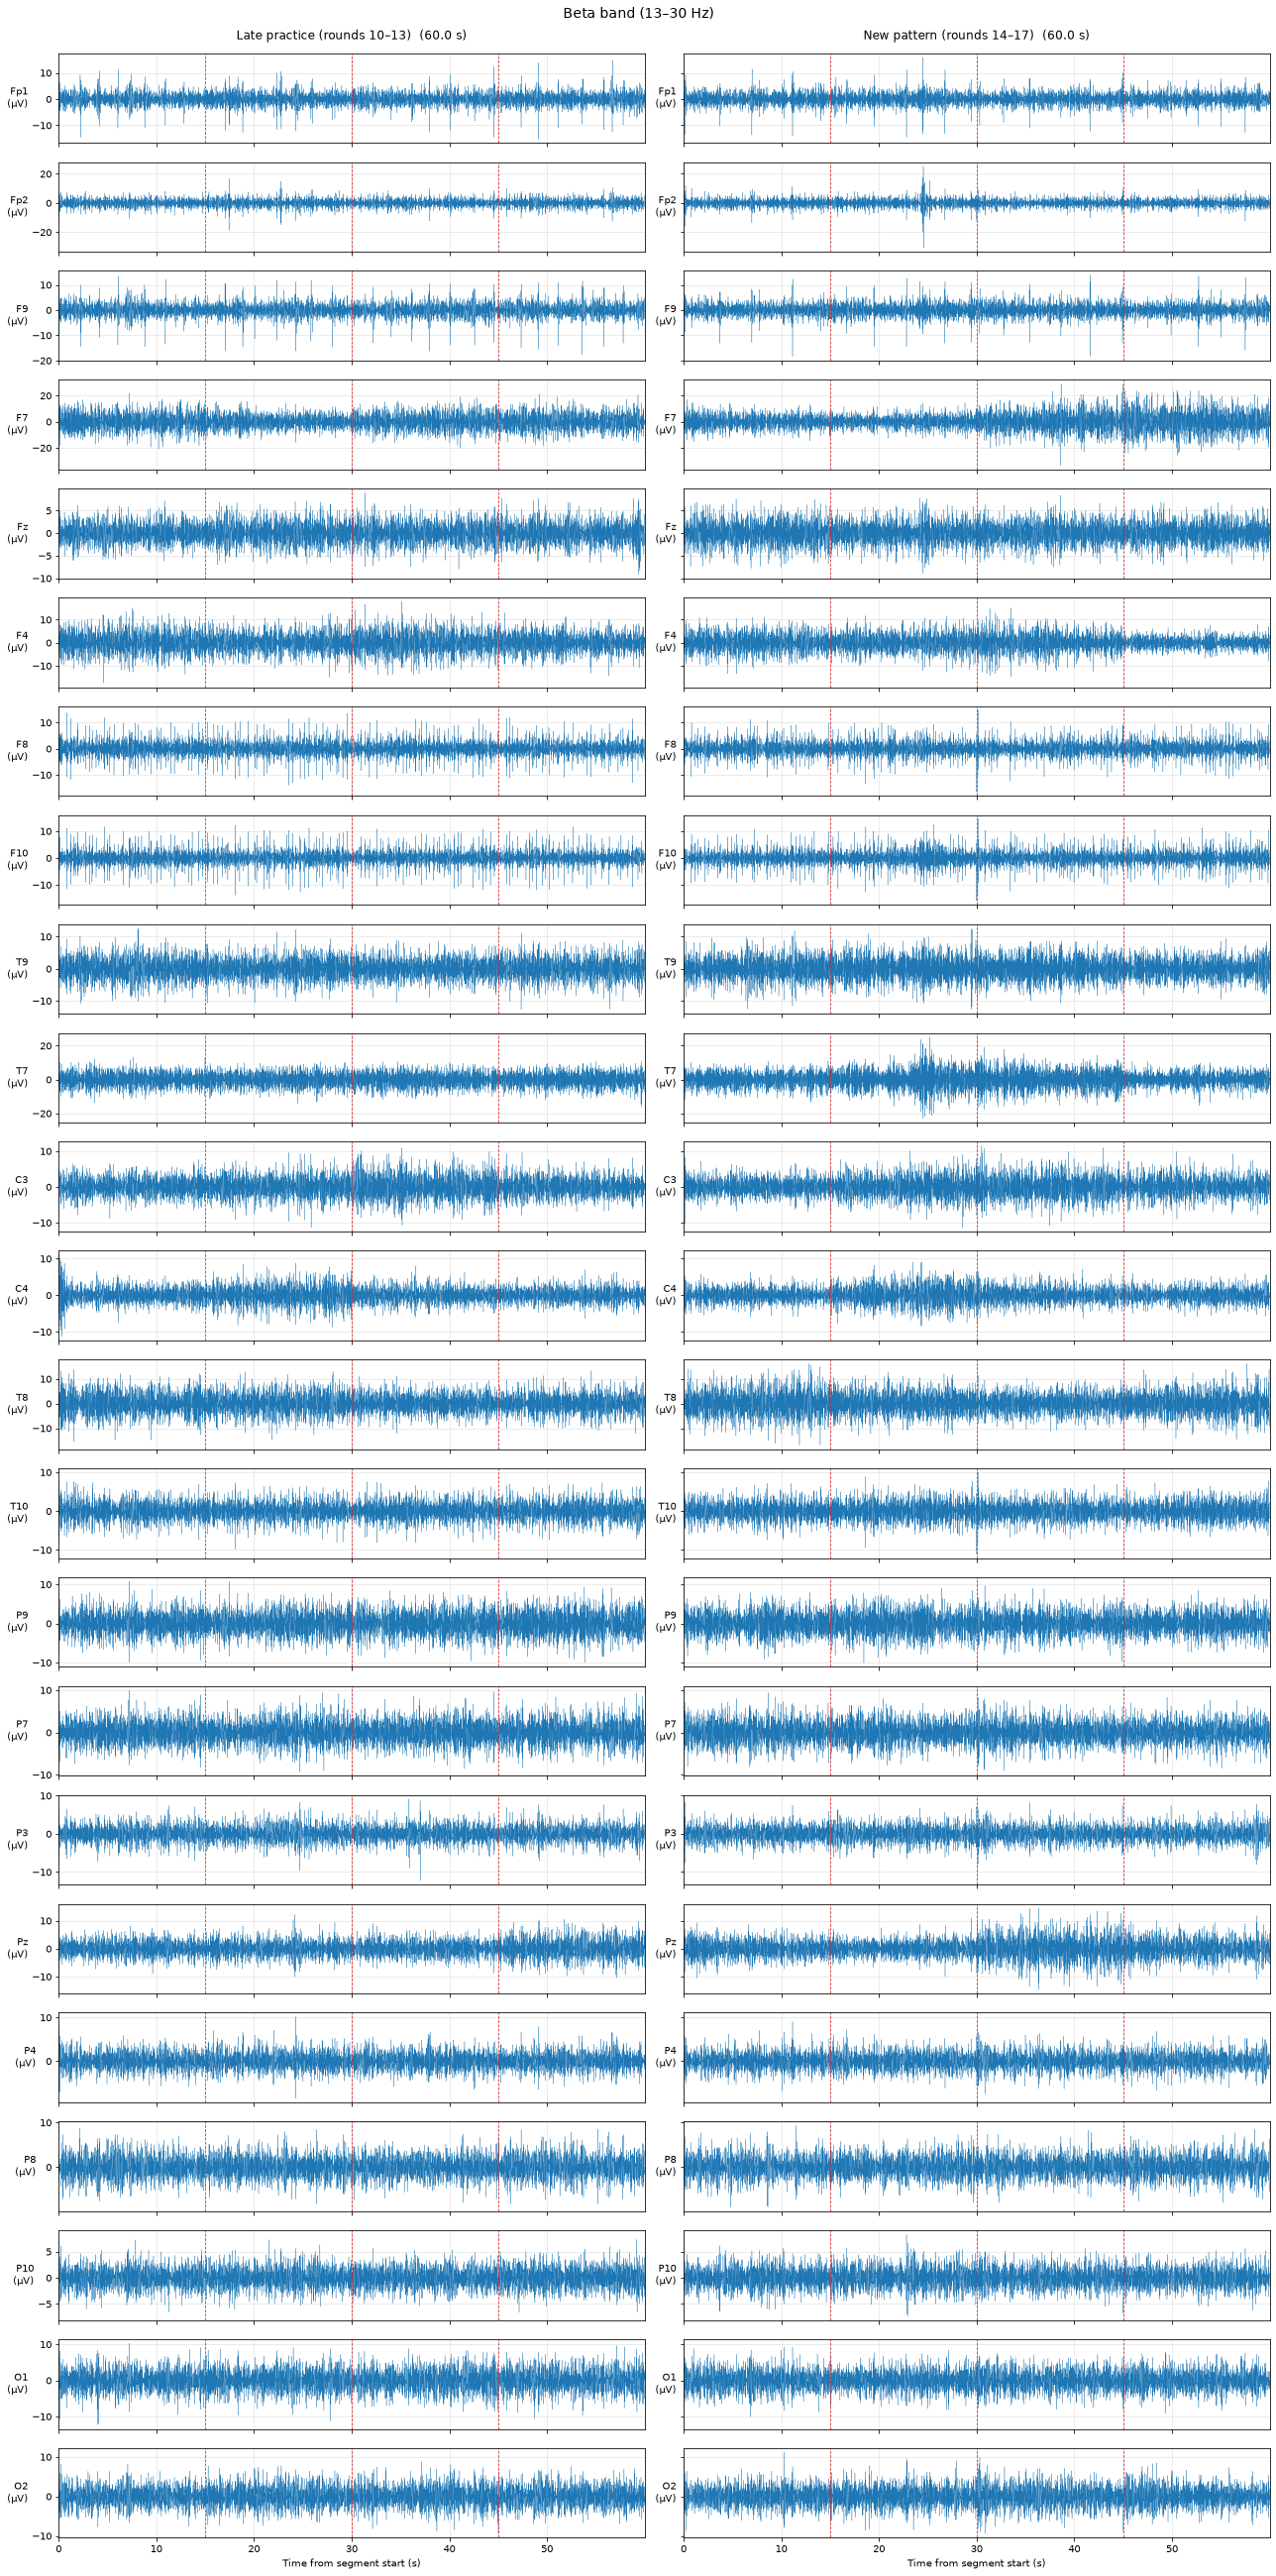

In [9]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 13, 30)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 13, 30))], late_new_labels, "Beta band (13–30 Hz)", marks=marks)

### 3.5 Gamma band (30–100 Hz)

**Why this plot:** gamma on the scalp is mostly muscle activity, so it shows whether muscle tension differed between patterns. It is a confound to watch, not a measure of effort.

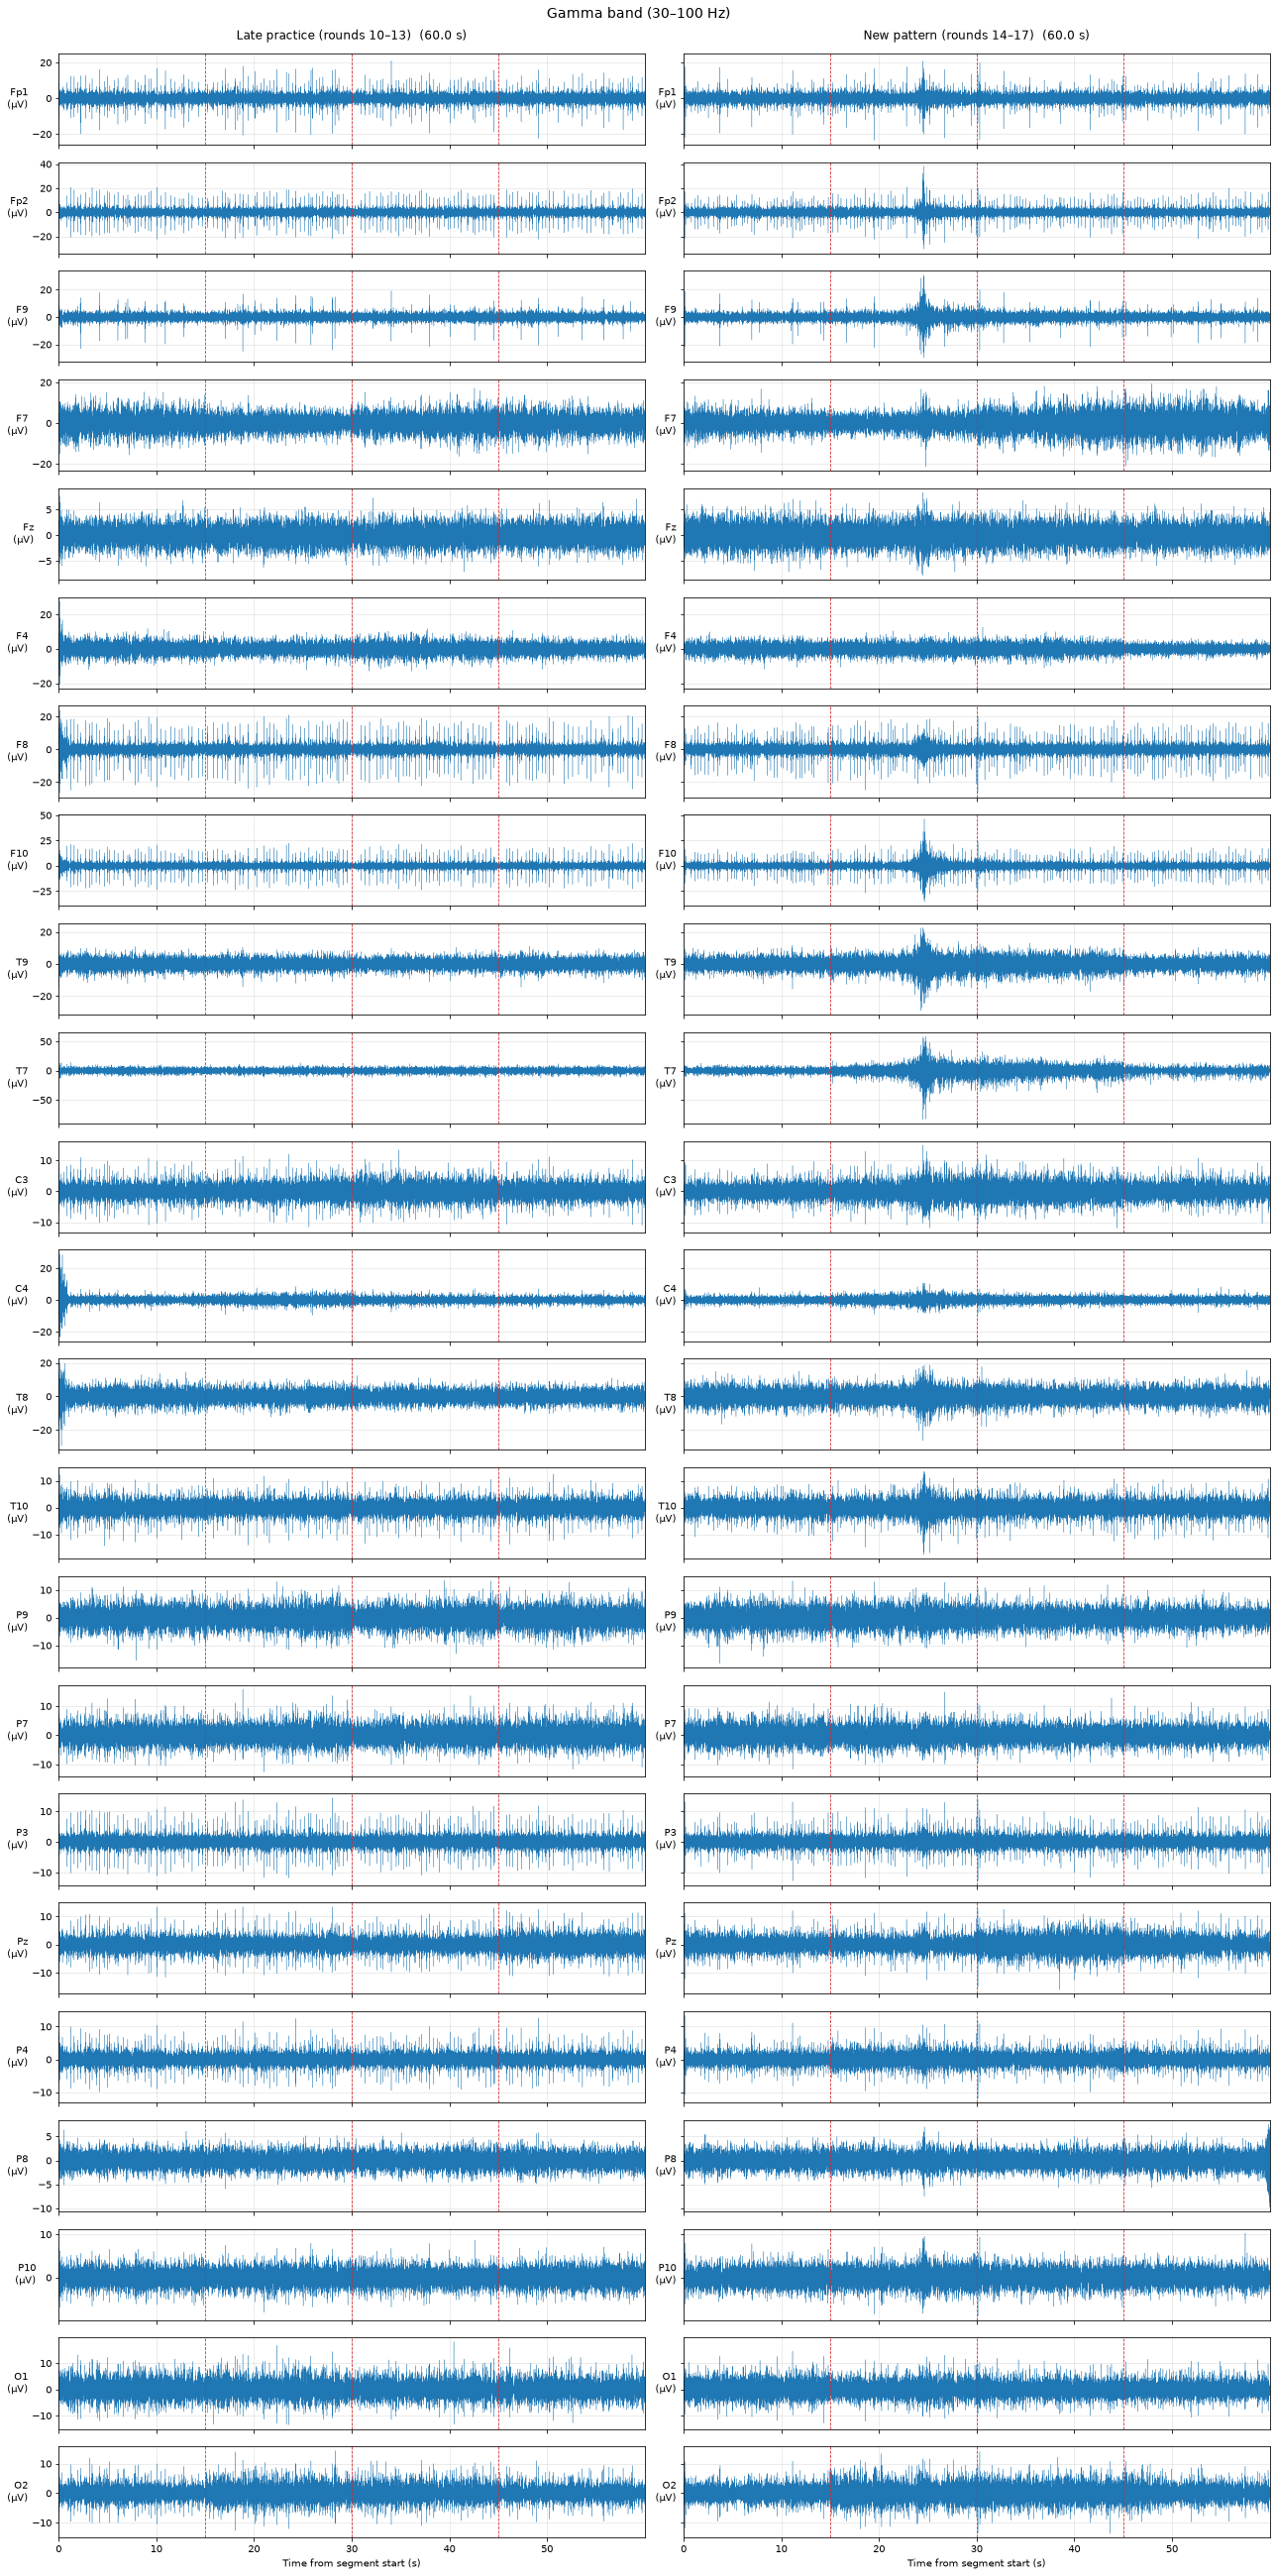

In [10]:
plot_segments([group_rounds(prepared, range(9, 13), lambda s: band_filter(s, 30, 99)), group_rounds(prepared, range(13, 17), lambda s: band_filter(s, 30, 99))], late_new_labels, "Gamma band (30–100 Hz)", marks=marks)

## 4. Frequency decomposition (FFT): late practice vs new pattern

Welch's method (2 s Hann windows, 50% overlap). Relative power is a band's share of 4–40 Hz.

**Why these plots:** the spectra show which frequencies carry the power for the practised and
the new pattern; the bars show across the head whether theta rises and alpha falls for the new one.

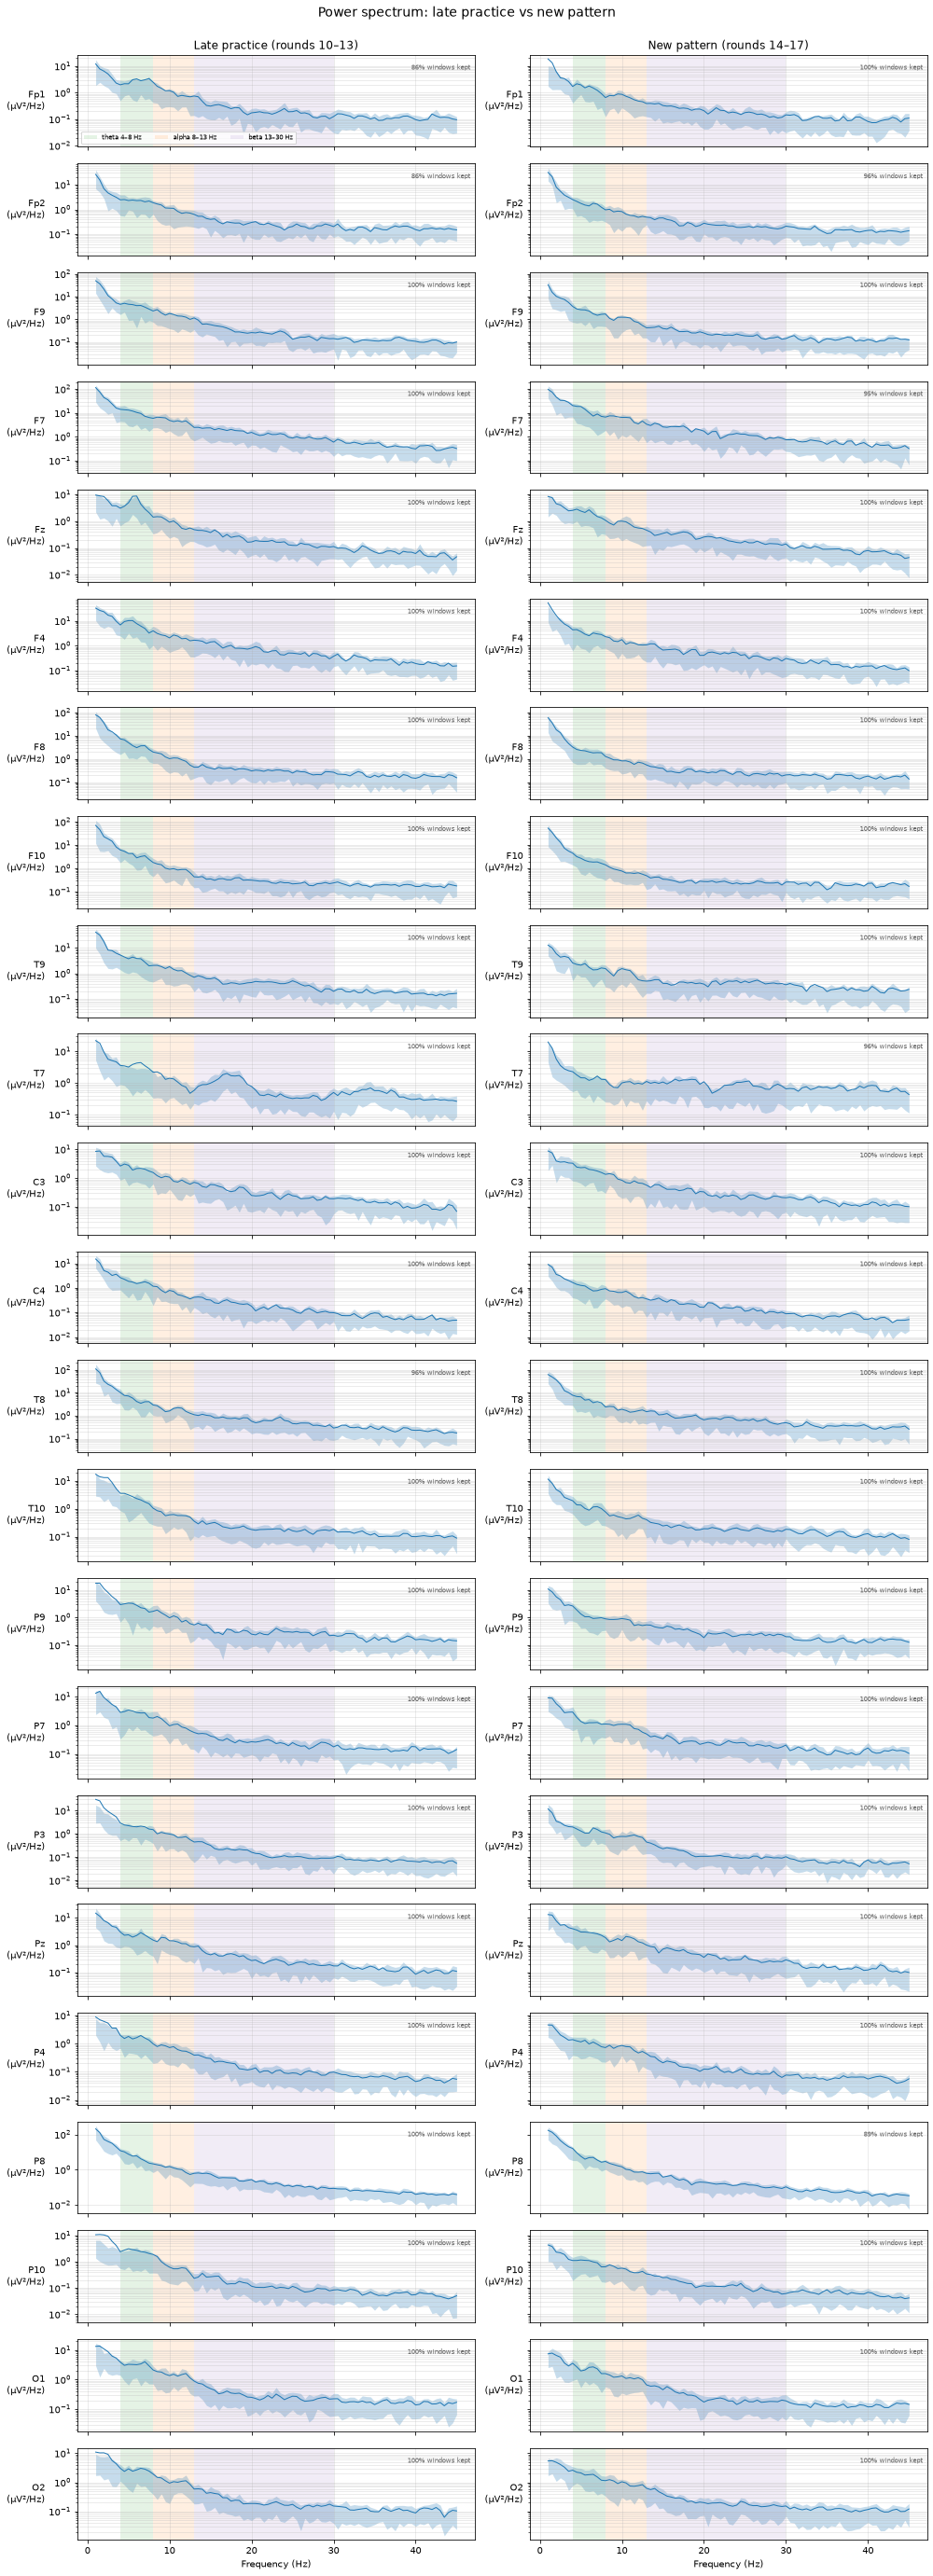

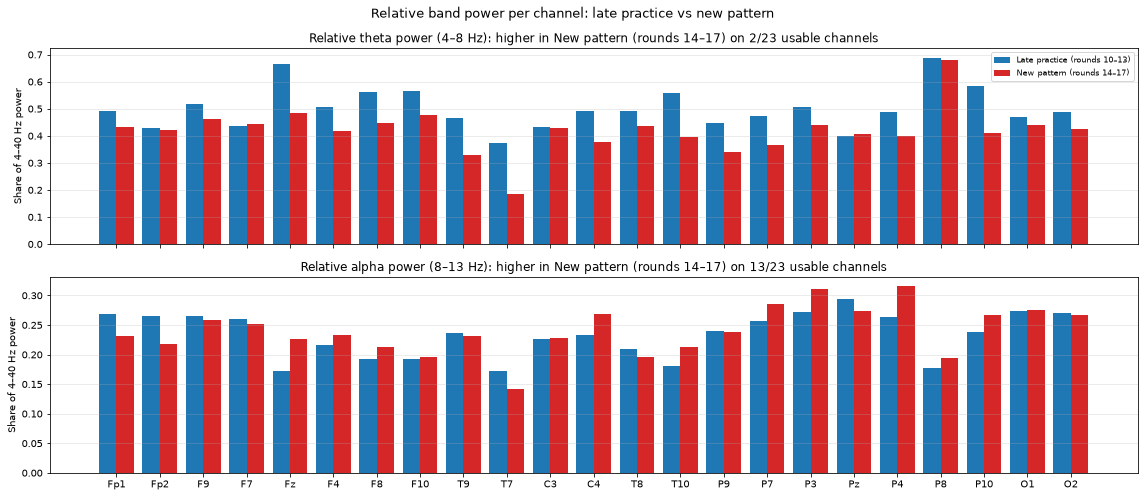

In [11]:
late_new = [phases["Late practice (rounds 10–13)"], phases["New pattern (rounds 14–17)"]]
late_new_spectra = [window_spectra(r) for r in late_new]
plot_spectra(late_new_spectra, late_new_labels, "Power spectrum: late practice vs new pattern")
plot_relative_bars(late_new_spectra, late_new_labels, "Relative band power per channel: late practice vs new pattern")

## 5. Cleaned analysis: ICA + theta/alpha above the 1/f background

One ICA is fitted on the whole session from the start of the baseline to the end of round 17
(rests included, transients excluded); ICLabel removes components confidently (probability ≥ 0.7)
classified as eye, muscle, heart, line noise or channel noise. FOOOF then measures theta
(Fz) and alpha (Pz) as power above the 1/f background, in dB.

ICA: 2 of 22 components removed: IC02 eye blink (1.00), IC03 eye blink (0.99)


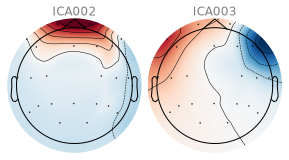

In [12]:
session_span = prepared.copy().crop(tmin=BASELINE[0], tmax=min(ROUNDS[-1, 1] + 5, prepared.times[-1]), verbose="error")
(clean_span,), ica_report, ica = ica_clean([session_span])
print(f"ICA: {int(ica_report.removed.sum())} of {len(ica_report)} components removed: "
      + ", ".join(f"{r.component} {r.label} ({r.probability:.2f})" for r in ica_report[ica_report.removed].itertuples()))
ica.plot_components(picks=ica.exclude, title="Components removed by ICLabel", show=False)
plt.show()
clean_phases = phase_data(clean_span)

### 5.1 Round by round

Theta above 1/f at Fz, alpha above 1/f at Pz and the 1/f exponent at Fz for every round
(15 s each), with the still baseline as a dashed line. The trend over the 13 practice rounds is
summarized with a Spearman correlation (descriptive).

**Why this plot:** learning should show as a gradual change across the practice rounds, and the
new pattern as a jump at round 14, so this shows the shape of both.

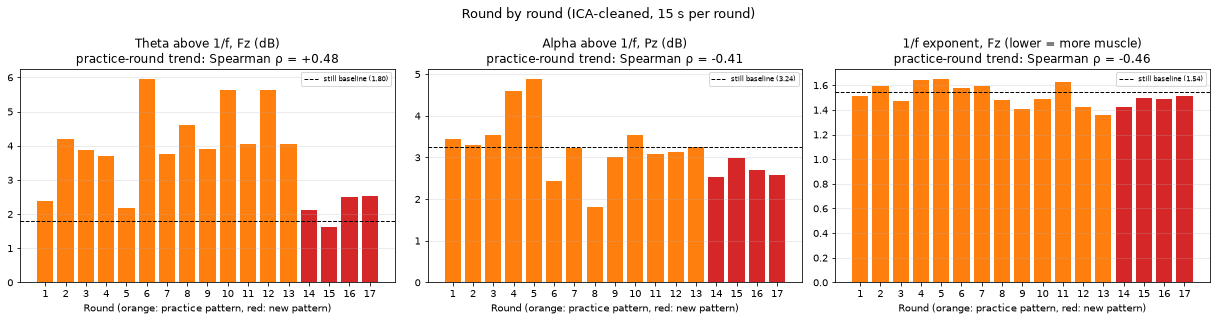

,round,pattern,theta_Fz_dB,alpha_Pz_dB,exponent_Fz,windows_clean_%
0,1,practice,2.38,3.45,1.51,100
1,2,practice,4.20,3.30,1.59,100
2,3,practice,3.88,3.53,1.47,100
3,4,practice,3.70,4.59,1.64,100
4,5,practice,2.17,4.88,1.65,100
5,6,practice,5.95,2.44,1.58,100
6,7,practice,3.77,3.23,1.59,100
7,8,practice,4.62,1.82,1.48,100
8,9,practice,3.89,3.00,1.41,100
9,10,practice,5.63,3.54,1.49,100


,theta_Fz_dB,alpha_Pz_dB,exponent_Fz
group,,,
Early practice (rounds 1–4),3.54,3.72,1.55
Middle practice (rounds 5–9),4.08,3.07,1.54
Late practice (rounds 10–13),4.84,3.25,1.48
New pattern (rounds 14–17),2.19,2.70,1.48


In [13]:
rows = []
for i, (a, b) in enumerate(ROUNDS):
    sp = roi_spectrum(window_spectra(cut(clean_span, a, b)), THETA_CHANNELS)
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    rows.append({"round": i + 1, "pattern": PATTERN[i], "theta_Fz_dB": m["theta_db"], "alpha_Pz_dB": m["alpha_db"],
                 "exponent_Fz": m[f"exponent_{THETA_SITE}"], "windows_clean_%": round(100 * sp[3][-1])})
per_round = pd.DataFrame(rows).round(2)
base = periodic_metrics(roi_spectrum(window_spectra(clean_phases["Baseline (still)"]), THETA_CHANNELS), THETA_SITE, ALPHA_SITE)
base_vals = {"theta_Fz_dB": base["theta_db"], "alpha_Pz_dB": base["alpha_db"], "exponent_Fz": base[f"exponent_{THETA_SITE}"]}

practice = per_round[per_round.pattern == "practice"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta_Fz_dB", "alpha_Pz_dB", "exponent_Fz"],
                          ["Theta above 1/f, Fz (dB)", "Alpha above 1/f, Pz (dB)", "1/f exponent, Fz (lower = more muscle)"]):
    rho = spearmanr(practice["round"], practice[col]).correlation
    ax.bar(per_round["round"], per_round[col], color=["C1" if p == "practice" else "C3" for p in per_round.pattern])
    ax.axhline(base_vals[col], color="k", ls="--", lw=1, label=f"still baseline ({base_vals[col]:.2f})")
    ax.set_xticks(per_round["round"])
    ax.set_xlabel("Round (orange: practice pattern, red: new pattern)")
    ax.set_title(f"{title}\npractice-round trend: Spearman ρ = {rho:+.2f}")
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Round by round (ICA-cleaned, 15 s per round)", fontsize=13)
fig.tight_layout()
plt.show()

group_means = per_round.assign(group=[next(g for g, idx in GROUPS.items() if r - 1 in idx) for r in per_round["round"]]) \
    .groupby("group", sort=False)[["theta_Fz_dB", "alpha_Pz_dB", "exponent_Fz"]].mean().round(2)
display(per_round)
display(group_means)

### 5.2 Hypothesis 1, learning: early practice (rounds 1–4) vs late practice (rounds 10–13)

**Why this plot:** if the practice pattern became easier, theta should be lower and alpha
higher in late practice; this compares every non-overlapping 2 s window of the two groups.

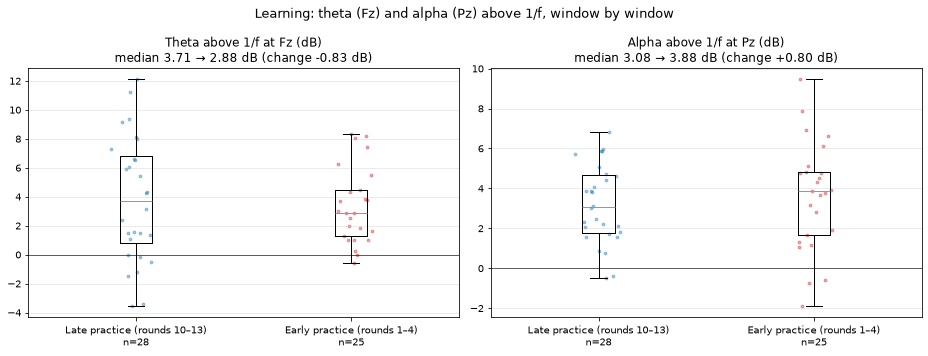

,Late practice (rounds 10–13),Early practice (rounds 1–4),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at Fz (dB),3.71,2.88,-0.83,0.60,0.40,28 / 25
Alpha above 1/f at Pz (dB),3.08,3.88,0.80,0.27,0.74,28 / 25


In [14]:
learn_labels = ["Late practice (rounds 10–13)", "Early practice (rounds 1–4)"]   # easier first, harder second
learn = [roi_spectrum(window_spectra(clean_phases[k], overlap=0.0), THETA_CHANNELS) for k in learn_labels]
periodic_workload_comparison(learn, learn_labels, "Learning: theta (Fz) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE)

### 5.3 Hypothesis 2, new pattern: late practice (rounds 10–13) vs new pattern (rounds 14–17)

**Why these plots:** the two groups are back to back in time, so a theta increase for the new
pattern would point to effort rather than fatigue; the spectra show whether it is a real theta
peak above the 1/f background.

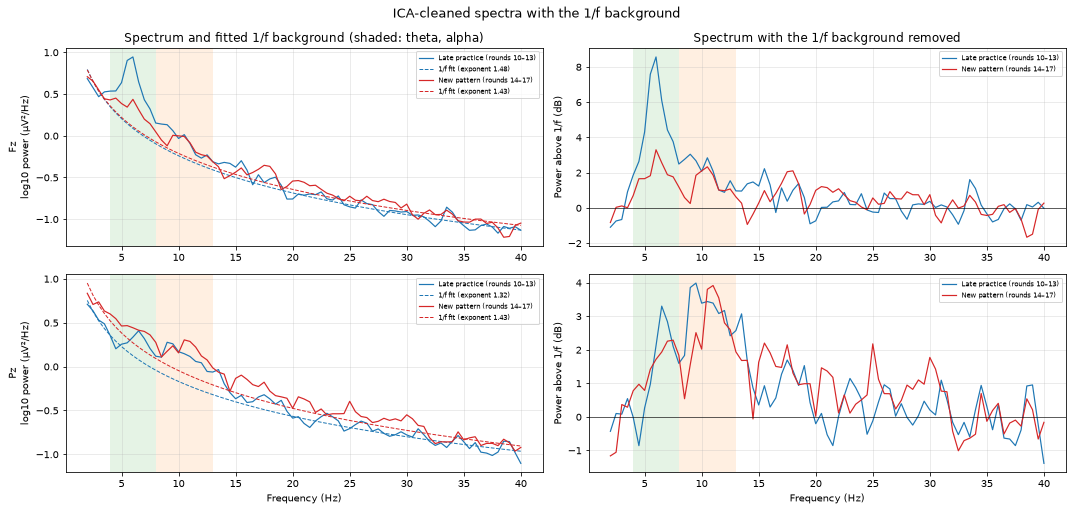

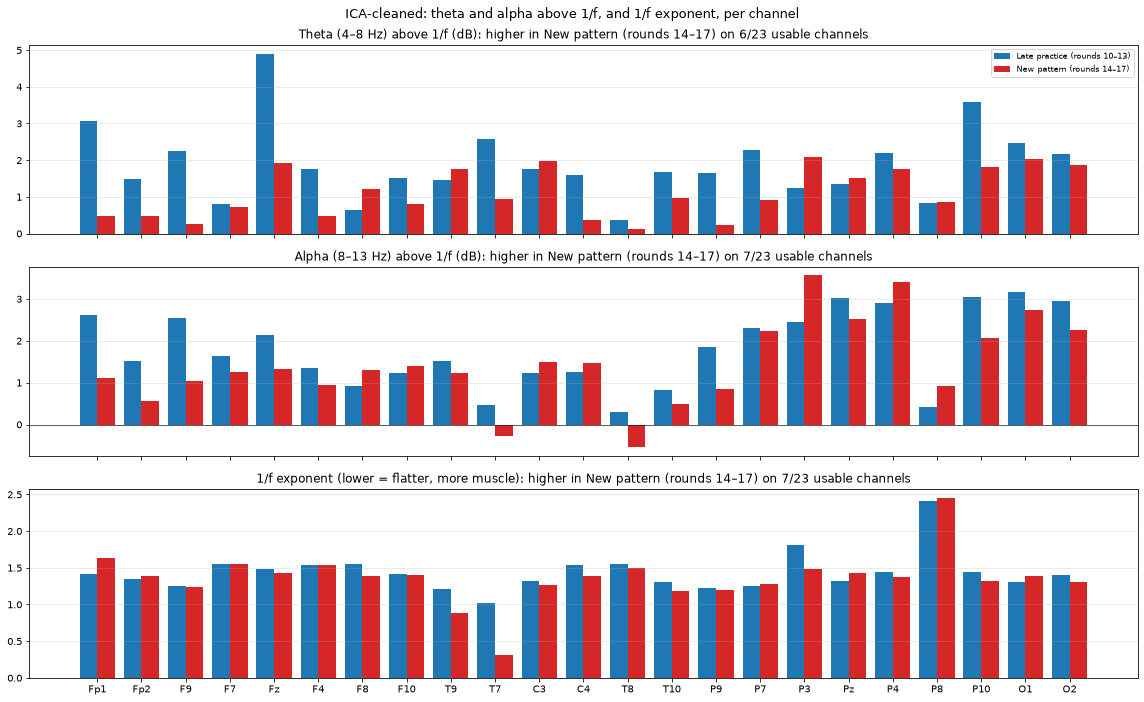

Late practice (rounds 10–13): theta Fz +4.91 dB, alpha Pz +3.02 dB (averaged spectrum)
New pattern (rounds 14–17): theta Fz +1.92 dB, alpha Pz +2.51 dB (averaged spectrum)


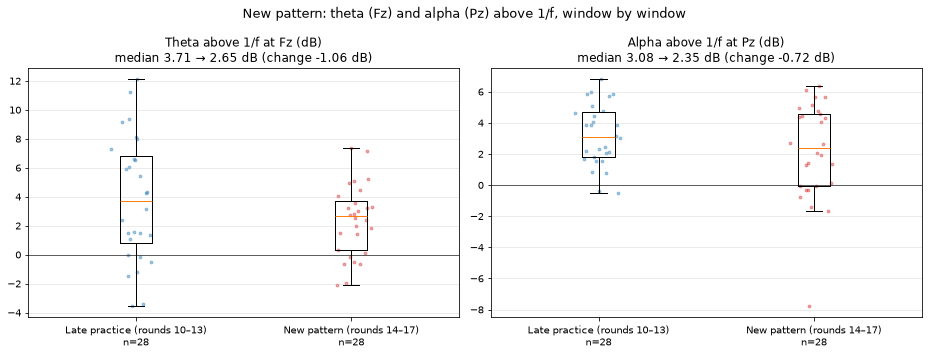

,Late practice (rounds 10–13),New pattern (rounds 14–17),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at Fz (dB),3.71,2.65,-1.06,0.88,0.12,28 / 28
Alpha above 1/f at Pz (dB),3.08,2.35,-0.72,0.86,0.15,28 / 28


In [15]:
novel_labels = ["Late practice (rounds 10–13)", "New pattern (rounds 14–17)"]
novel = [roi_spectrum(window_spectra(clean_phases[k]), THETA_CHANNELS) for k in novel_labels]
plot_fooof_fits(novel, novel_labels, "ICA-cleaned spectra with the 1/f background", channels=(THETA_SITE, ALPHA_SITE))
plot_periodic_bars([(p[:, :-1], f, c[:-1], k[:-1]) for p, f, c, k in novel], novel_labels,
                   "ICA-cleaned: theta and alpha above 1/f, and 1/f exponent, per channel")
for label, sp in zip(novel_labels, novel):
    m = periodic_metrics(sp, THETA_SITE, ALPHA_SITE)
    print(f"{label}: theta Fz {m['theta_db']:+.2f} dB, alpha Pz {m['alpha_db']:+.2f} dB (averaged spectrum)")
novel_nonoverlap = [roi_spectrum(window_spectra(clean_phases[k], overlap=0.0), THETA_CHANNELS) for k in novel_labels]
periodic_workload_comparison(novel_nonoverlap, novel_labels, "New pattern: theta (Fz) and alpha (Pz) above 1/f, window by window",
                             theta_ch=THETA_SITE, alpha_ch=ALPHA_SITE)

## 6. Results: do the data support the hypotheses?

**Partly, and the pattern repeats Session 3 Part 2. Parietal alpha drops for the new pattern
(hypothesis 2), as it did there. Frontal-midline theta, now measured at a working Fz, rises over
the practice rounds and drops sharply for the new pattern, the opposite of both hypotheses, again
as in Session 3 Part 2.**

| Measure (ICA-cleaned, above 1/f) | Early practice (1–4) | Late practice (10–13) | New pattern (14–17) | Still baseline |
|---|---|---|---|---|
| Theta at Fz, mean of rounds | 3.54 dB | 4.84 dB | 2.19 dB | 1.80 dB |
| Alpha at Pz, mean of rounds | 3.72 dB | 3.25 dB | 2.70 dB | 3.24 dB |
| 1/f exponent at Fz, mean of rounds | 1.55 | 1.48 | 1.48 | 1.54 |

**Hypothesis 1, learning (early vs late practice): not supported.**
- **Theta at Fz rose** over the 13 practice rounds (Spearman ρ = +0.48; 3.54 → 4.84 dB; window
  median +0.8 dB), where learning predicts a fall.
- **Alpha at Pz fell** (ρ = −0.41; 3.72 → 3.25 dB; window median −0.8 dB), where learning predicts a rise.
  Both changes point to load increasing over the practice rounds, or to time on task, not to the pattern getting easier.

**Hypothesis 2, new pattern (late practice vs new pattern): alpha yes, theta no.**
- **Alpha at Pz dropped:** −0.55 dB (mean of rounds), −0.51 dB (averaged spectrum, 3.02 → 2.51 dB),
  −0.72 dB (window median, descriptive p = 0.15). All four new-pattern rounds are below the late-practice
  average. Same direction as Session 3 Part 2 (−0.7 to −1.5 dB there), though smaller.
- **Theta at Fz dropped sharply:** −2.65 dB (mean of rounds), −3.0 dB (averaged spectrum, 4.91 → 1.92 dB),
  −1.06 dB (window median). The new-pattern rounds fall back to the still-baseline level.
- **The 1/f exponent is the same** for late practice and the new pattern (1.48 both), so neither change is
  explained by a change in muscle activity.

**What Session 4 adds to Session 3 Part 2:**
- **The theta pattern replicates with a working Fz.** In Session 3, theta had to be measured at F3+F4,
  and Session 1 suggested F3+F4 can miss frontal-midline theta. Here Fz itself shows the same thing:
  theta builds up over practice and collapses when the pattern changes. So the "wrong-way" theta result
  isn't an artifact of the electrode substitute.
- **The alpha drop for the new pattern replicates,** which makes it the most consistent effort-related
  signal across the finger-tapping sessions.
- **One plausible reading:** frontal-midline theta here tracks engagement with the *practised* sequence
  (it grows as the sequence is rehearsed) rather than effort, and resets when the sequence changes,
  while parietal alpha drops when a new sequence needs attention.

**Limits:**
- **No timing notes:** the schedule was located from the data (eye activity drops in all 17 rounds; the
  signal repeats every 25.0 s; best fit r = −0.57). The protocol, 30 s baseline then 13 practice and 4
  new-pattern rounds, is assumed to match Session 3 Part 2.
- **Transients** (largest 9.7 mV at 169 s, in round 6) are excluded; ICA removed 2 eye components; F3 is excluded.
- **One session, 15 s rounds:** single rounds are noisy, and p-values are descriptive only.

## 7. Theta power check

### 7.1 Definition

**Theta power** at a channel is the total power of the EEG between 4 and 8 Hz:

$$\theta = \int_{4\,\mathrm{Hz}}^{8\,\mathrm{Hz}} P(f)\,df \;\approx\; \sum_{4 \le f_k < 8} P(f_k)\,\Delta f \qquad [\mu V^2]$$

- **P(f)** is the power spectral density (µV²/Hz), estimated with Welch's method on the ICA-cleaned,
  average-referenced data: 2 s Hann windows with 50% overlap (Δf = 0.5 Hz), averaged over the clean
  windows of the period (a round, the baseline, or a group of rounds).
- By Parseval's theorem this equals the **variance of the signal band-passed to 4–8 Hz**, which is
  used below as an independent check.
- It is reported in **dB**: 10·log₁₀(θ / 1 µV²). A change of +1 dB is about 26% more power.

This is **absolute** theta power. Sections 4–6 used two measures derived from it, which can move
differently:
- **Relative theta:** θ ÷ (4–40 Hz power), so it also changes when other bands change.
- **Theta above 1/f:** only the part of the 4–8 Hz spectrum that sticks out above the fitted 1/f
  background, so it ignores changes in the background itself.

Absolute power is comparable across rounds here because Session 4 is one continuous recording with
no impedance re-check in between (unlike the paused segments of the other sessions, where electrode
contact changes between segments).

**"Increasing"** is checked two ways: the trend over the 13 practice rounds (Spearman ρ, descriptive),
and the means of the round groups (baseline, early, middle and late practice, new pattern).

In [16]:
import warnings

THETA = (4.0, 8.0)


def theta_power_welch(raw):
    """Absolute theta power per channel (µV²): Welch PSD averaged over clean windows, integrated over 4–8 Hz."""
    psd, f, chs, keep = window_spectra(raw)
    m = (f >= THETA[0]) & (f < THETA[1])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)   # a channel with no clean windows -> NaN
        mean_psd = np.nanmean(psd, axis=0)
    return dict(zip(chs, mean_psd[:, m].sum(axis=1) * (f[1] - f[0])))


def theta_power_bandpass(raw):
    """Same quantity via Parseval: variance of the signal after an ideal (brick-wall) 4–8 Hz band-pass,
    done with an FFT so exactly 4–8 Hz is kept (bad spans omitted, 1 Hz high-pass as for Welch)."""
    x = raw.copy().filter(l_freq=1.0, h_freq=None, verbose="error").get_data(reject_by_annotation="omit", verbose="error") * 1e6
    spec = np.fft.rfft(x - x.mean(axis=1, keepdims=True), axis=1)
    f = np.fft.rfftfreq(x.shape[1], 1 / raw.info["sfreq"])
    spec[:, (f < THETA[0]) | (f >= THETA[1])] = 0
    return dict(zip(raw.ch_names, np.fft.irfft(spec, n=x.shape[1], axis=1).var(axis=1)))


def db(x):
    return 10 * np.log10(x)


def add_roi(d):
    d = dict(d)
    d[THETA_SITE] = np.mean([d[c] for c in THETA_CHANNELS])
    return d


periods = {f"Round {i + 1}": cut(clean_span, *ROUNDS[i]) for i in range(len(ROUNDS))}
periods["Baseline (still)"] = clean_phases["Baseline (still)"]
theta_welch = {k: add_roi(theta_power_welch(v)) for k, v in periods.items()}
theta_bp = {k: add_roi(theta_power_bandpass(v)) for k, v in periods.items()}

# Cross-check the two ways of computing theta power
diff = np.array([db(theta_welch[k][THETA_SITE]) - db(theta_bp[k][THETA_SITE]) for k in periods])
print(f"Welch integral vs variance of the 4–8 Hz band-passed signal at {THETA_SITE}: mean difference {diff.mean():+.2f} dB, "
      f"largest {np.abs(diff).max():.2f} dB across {len(periods)} periods")

Welch integral vs variance of the 4–8 Hz band-passed signal at Fz: mean difference +0.13 dB, largest 1.08 dB across 18 periods


### 7.2 Theta power at Fz, round by round, under each definition

**Why this plot:** it shows whether theta is increasing when measured as absolute power, and whether
the rise reported in section 6 comes from theta itself or from how it was normalized.

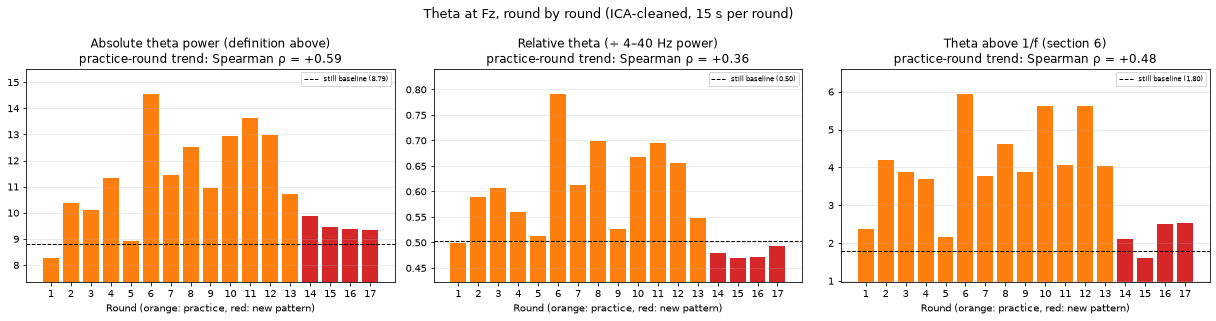

,round,pattern,theta Fz (dB µV²),relative theta Fz,theta above 1/f Fz (dB)
0,1,practice,8.278,0.499,2.38
1,2,practice,10.372,0.589,4.20
2,3,practice,10.110,0.606,3.88
3,4,practice,11.335,0.560,3.70
4,5,practice,8.912,0.513,2.17
5,6,practice,14.565,0.792,5.95
6,7,practice,11.464,0.612,3.77
7,8,practice,12.527,0.698,4.62
8,9,practice,10.967,0.527,3.89
9,10,practice,12.959,0.668,5.63


,theta Fz (dB µV²),theta F4 (dB µV²),theta Pz (dB µV²)
Baseline (still),8.79,9.30,5.37
Early practice (rounds 1–4),10.16,11.24,8.53
Middle practice (rounds 5–9),12.08,11.28,8.57
Late practice (rounds 10–13),12.70,14.20,9.02
New pattern (rounds 14–17),9.52,11.15,10.70


In [17]:
from processing.analysis import BANDS, relative_power

rel_rows = []
for i in range(len(ROUNDS)):
    sp = roi_spectrum(window_spectra(periods[f"Round {i + 1}"]), THETA_CHANNELS)
    rel_rows.append(relative_power(sp, BANDS["theta"])[-1])

theta_table = pd.DataFrame({
    "round": range(1, len(ROUNDS) + 1),
    "pattern": PATTERN,
    "theta Fz (dB µV²)": [db(theta_welch[f"Round {i}"]["Fz"]) for i in range(1, len(ROUNDS) + 1)],
    "relative theta Fz": rel_rows,
    "theta above 1/f Fz (dB)": per_round["theta_Fz_dB"].values,
}).round(3)
baseline_row = {"theta Fz (dB µV²)": db(theta_welch["Baseline (still)"][THETA_SITE]),
                "relative theta Fz": relative_power(roi_spectrum(window_spectra(periods["Baseline (still)"]), THETA_CHANNELS), BANDS["theta"])[-1],
                "theta above 1/f Fz (dB)": base_vals["theta_Fz_dB"]}

practice_rows = theta_table[theta_table.pattern == "practice"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, title in zip(axes, ["theta Fz (dB µV²)", "relative theta Fz", "theta above 1/f Fz (dB)"],
                          ["Absolute theta power (definition above)", "Relative theta (÷ 4–40 Hz power)", "Theta above 1/f (section 6)"]):
    rho = spearmanr(practice_rows["round"], practice_rows[col]).correlation
    ax.bar(theta_table["round"], theta_table[col], color=["C1" if p == "practice" else "C3" for p in PATTERN])
    ax.axhline(baseline_row[col], color="k", ls="--", lw=1, label=f"still baseline ({baseline_row[col]:.2f})")
    lo, hi = theta_table[col].min(), theta_table[col].max()
    ax.set_ylim(lo - 0.15 * (hi - lo), hi + 0.15 * (hi - lo))
    ax.set_xticks(theta_table["round"])
    ax.set_xlabel("Round (orange: practice, red: new pattern)")
    ax.set_title(f"{title}\npractice-round trend: Spearman ρ = {rho:+.2f}")
    ax.legend(fontsize=7)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Theta at {THETA_SITE}, round by round (ICA-cleaned, 15 s per round)", fontsize=13)
fig.tight_layout()
plt.show()

groups = {"Baseline (still)": ["Baseline (still)"]}
groups.update({g: [f"Round {i + 1}" for i in idx] for g, idx in GROUPS.items()})
group_theta = pd.DataFrame({
    ch: [db(np.mean([theta_welch[p][ch] for p in members])) for members in groups.values()]
    for ch in ["Fz", "F4", "Pz"]
}, index=list(groups)).round(2)
group_theta.columns = [f"theta {c} (dB µV²)" for c in group_theta.columns]
display(theta_table)
display(group_theta)

### 7.3 Every channel

Theta power is also measured on every channel (the band plots and per-channel bars in sections 3–5),
so the same check is repeated for all of them.

**Why this plot:** it shows whether a theta increase is specific to the frontal channels or happens
across the whole head, which would point to something global (time on task, arousal) rather than
frontal effort.

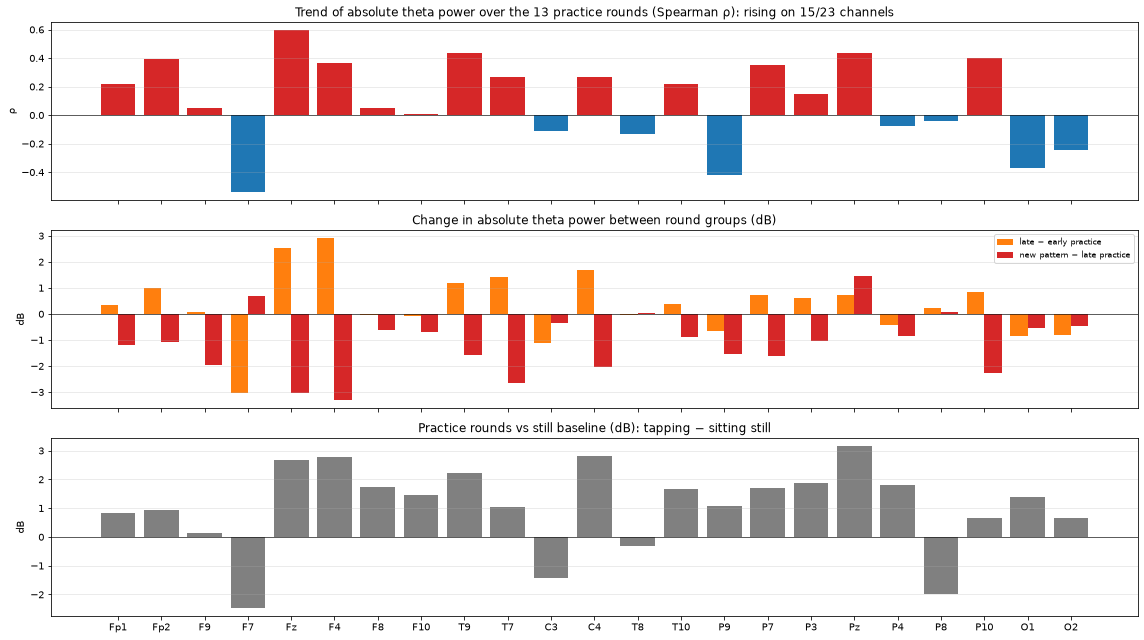

Rounds without clean windows (left out of that channel's averages): {'P8': [2]}
Rising over practice (ρ > 0): 15/23 channels; median ρ +0.15
Late − early practice: higher on 14/23 channels, median +0.35 dB
New pattern − late practice: higher on 4/23 channels, median -1.03 dB
Practice − baseline: higher on 19/23 channels, median +1.38 dB


In [18]:
channels = list(clean_span.ch_names)
rounds_db = np.array([[db(theta_welch[f"Round {i + 1}"][c]) for c in channels] for i in range(len(ROUNDS))])
practice_idx = [i for i, p in enumerate(PATTERN) if p == "practice"]
trend = np.array([spearmanr(range(len(practice_idx)), rounds_db[practice_idx, j], nan_policy="omit").correlation
                  for j in range(len(channels))])
late = np.nanmean(rounds_db[list(GROUPS["Late practice (rounds 10–13)"])], axis=0)
early = np.nanmean(rounds_db[list(GROUPS["Early practice (rounds 1–4)"])], axis=0)
new = np.nanmean(rounds_db[list(GROUPS["New pattern (rounds 14–17)"])], axis=0)
practice_mean = np.nanmean(rounds_db[practice_idx], axis=0)
base_db = np.array([db(theta_welch["Baseline (still)"][c]) for c in channels])
missing = {c: [i + 1 for i in range(len(ROUNDS)) if np.isnan(rounds_db[i, j])] for j, c in enumerate(channels) if np.isnan(rounds_db[:, j]).any()}

x = np.arange(len(channels))
fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
axes[0].bar(x, trend, color=["C3" if v > 0 else "C0" for v in trend])
axes[0].set_title(f"Trend of absolute theta power over the 13 practice rounds (Spearman ρ): rising on "
                  f"{int(np.nansum(trend > 0))}/{len(channels)} channels")
axes[0].set_ylabel("ρ")
axes[1].bar(x - 0.2, late - early, 0.4, label="late − early practice", color="C1")
axes[1].bar(x + 0.2, new - late, 0.4, label="new pattern − late practice", color="C3")
axes[1].set_title("Change in absolute theta power between round groups (dB)")
axes[1].set_ylabel("dB")
axes[1].legend(fontsize=8)
axes[2].bar(x, practice_mean - base_db, color="0.5")
axes[2].set_title("Practice rounds vs still baseline (dB): tapping − sitting still")
axes[2].set_ylabel("dB")
for ax in axes:
    ax.axhline(0, color="k", lw=0.6)
    ax.grid(axis="y", alpha=0.3)
axes[-1].set_xticks(x, channels)
fig.tight_layout()
plt.show()
print(f"Rounds without clean windows (left out of that channel's averages): {missing or 'none'}")
print(f"Rising over practice (ρ > 0): {int(np.nansum(trend > 0))}/{len(channels)} channels; median ρ {np.nanmedian(trend):+.2f}")
print(f"Late − early practice: higher on {int(np.nansum(late > early))}/{len(channels)} channels, median {np.nanmedian(late - early):+.2f} dB")
print(f"New pattern − late practice: higher on {int(np.nansum(new > late))}/{len(channels)} channels, median {np.nanmedian(new - late):+.2f} dB")
print(f"Practice − baseline: higher on {int(np.nansum(practice_mean > base_db))}/{len(channels)} channels, "
      f"median {np.nanmedian(practice_mean - base_db):+.2f} dB")

### 7.4 Is theta power increasing?

**Over the practice rounds, yes; for the new pattern, no: it falls back to near baseline.
The same holds under all three definitions, as in Session 3 Part 2.**

| Theta power at Fz (absolute, dB µV²) | Value | Change |
|---|---|---|
| Still baseline | 8.79 | |
| Early practice (rounds 1–4) | 10.16 | +1.4 vs baseline |
| Middle practice (rounds 5–9) | 12.08 | +1.9 vs early |
| Late practice (rounds 10–13) | 12.70 | **+2.5 vs early** |
| New pattern (rounds 14–17) | 9.52 | **−3.2 vs late** |

- **Same direction under every definition:** the practice-round trend at Fz is ρ = +0.59 (absolute power),
  +0.36 (relative) and +0.48 (above 1/f), and all three drop for the new pattern (relative theta falls
  from about 0.65 to 0.48, below the baseline's 0.50).
- **Computed correctly:** the Welch integral and the variance of the 4–8 Hz band-passed signal agree
  within 0.13 dB on average across the 18 periods (at most 1.1 dB, in one 15 s round).
- **Less global than in Session 3 Part 2:** theta rises over practice on 15 of 23 channels (median ρ = +0.15;
  there it was 19 of 21). The increase is clearest at Fz and F4 (+2.5 to +2.9 dB late vs early); 9 channels go the other
  way, most strongly F7 (−3.0 dB) and C3 (−1.1 dB). During tapping theta is higher than at baseline on 19 of 23 channels (median +1.4 dB).
- **The drop for the new pattern is widespread:** lower than late practice on 19 of 23 channels
  (median −1.0 dB), largest at Fz and F4 (about −3 dB). Pz is an exception (+1.5 to +1.7 dB).
- P8 had no clean windows in round 2 and is left out of that round's averages.